# Example 05 — Inverse design (Ax)

Two continuous KPIs (`permeance`, `rejection`). After training, **Ax** searches recipe-like numbers.

**Inverse design** = we know the performance we want and search for inputs. The optimizer only queries the **model**, not the lab.

This example uses a **scalarized** (weighted) score so it finishes quickly: `0.3 * permeance + 0.7 * rejection` (after scaling). Changing 0.3 / 0.7 changes what “best” means.

The **full tutorial** uses **true multiobjective / Pareto** search (a *set* of recipes along the trade-off). You can switch this example to that mode (below).

Needs `pip install -e ".[opt]"` (Colab bootstrap). First install can take several minutes. `n_trials` is small on purpose. Suggestions are **not** a lab-proven membrane.

```bash
python -m run_pipeline --config examples/05_inverse_design_controls/config.yaml --force-retrain
```

[Open in Colab](https://colab.research.google.com/github/Oikiy/ML-MEM-Review/blob/main/examples/05_inverse_design_controls/Colab.ipynb)


## 1. Bootstrap (Colab clone + install)

This `.ipynb` is not the whole **repository** (`config.yaml`, `src/`, data).

> **Next cell:** on Colab, clone/update `/content/ML-MEM-Review` and pip-install. First install can take a few minutes. No Google Drive. Locally: find the repo (example 05 installs Ax if missing).

### How to read the output

`Repo root: ...` and `Colab bootstrap done.`

---

**Watch out.** Do not run later cells first. Expand the hidden **Bootstrap** form if clone/install fails. Then run **in order**.


In [1]:
# @title Bootstrap (clone + install)
# === COLAB BOOTSTRAP (safe locally) =========================================
import os
import sys
import subprocess
from pathlib import Path

def _in_colab() -> bool:
    try:
        import google.colab  # noqa: F401
        return True
    except ImportError:
        return False

def _run(cmd, **kwargs):
    print("+", " ".join(cmd) if isinstance(cmd, (list, tuple)) else cmd)
    subprocess.check_call(cmd, **kwargs)

def _find_repo_root(start: Path):
    start = start.resolve()
    for candidate in [start, *start.parents]:
        if (candidate / "config.yaml").is_file() and (candidate / "src").is_dir():
            return candidate
    return None

try:
    get_ipython().run_line_magic("matplotlib", "inline")
except Exception:
    pass

IN_COLAB = _in_colab()
REPO_URL = os.environ.get("ML_MEM_REPO_URL", "https://github.com/Oikiy/ML-MEM-Review.git")
REPO_NAME = os.environ.get("ML_MEM_REPO_NAME", "ML-MEM-Review")
REPO_REF = os.environ.get("ML_MEM_REPO_REF", "main")
COLAB_ROOT = Path(os.environ.get("ML_MEM_COLAB_ROOT", f"/content/{REPO_NAME}"))
EXTRAS = 'opt'

def _git_head(repo: Path) -> str:
    try:
        return subprocess.check_output(
            ["git", "-C", str(repo), "rev-parse", "HEAD"], text=True
        ).strip()
    except (subprocess.CalledProcessError, FileNotFoundError, OSError):
        return ""

def _truthy(name: str) -> bool:
    return os.environ.get(name, "").strip().lower() in {"1", "true", "yes"}

if IN_COLAB:
    try:
        if COLAB_ROOT.exists() and (COLAB_ROOT / ".git").is_dir():
            if _truthy("ML_MEM_SKIP_PULL"):
                print(f"Skipping git update at {COLAB_ROOT} (ML_MEM_SKIP_PULL=1)")
            else:
                print(f"Updating clone at {COLAB_ROOT} to origin/{REPO_REF}")
                _run(["git", "-C", str(COLAB_ROOT), "fetch", "--depth", "1", "origin", REPO_REF])
                _run(["git", "-C", str(COLAB_ROOT), "reset", "--hard", "FETCH_HEAD"])
        elif not COLAB_ROOT.exists():
            _run(["git", "clone", "--depth", "1", "--branch", REPO_REF, REPO_URL, str(COLAB_ROOT)])
        os.chdir(COLAB_ROOT)
    except subprocess.CalledProcessError as exc:
        raise RuntimeError(
            "git clone/update failed. Make the repo public, set ML_MEM_REPO_URL "
            f"to a fork, or set ML_MEM_REPO_REF. Original error: {exc}"
        ) from exc
    root = _find_repo_root(Path.cwd())
else:
    root = _find_repo_root(Path.cwd())

if root is None:
    raise RuntimeError(
        "Could not locate ML-MEM-Review (need config.yaml + src/). "
        "On Colab: re-run this cell after a successful clone. "
        "Locally: open from inside a full clone of the repository."
    )

os.chdir(root)
print(f"Repo root: {root}  git={_git_head(root)[:12]}")

src = root / "src"
if str(src) not in sys.path:
    sys.path.insert(0, str(src))

if IN_COLAB:
    marker = root / ".colab_install_ok"
    force = _truthy("ML_MEM_FORCE_INSTALL")
    head = _git_head(root)
    extras = EXTRAS
    pip_spec = str(root) if not extras else f"{root}[{extras}]"
    install_key = f"{head}\n{extras}"
    prev = marker.read_text(encoding="utf-8").strip() if marker.is_file() else ""
    if force or prev != install_key:
        _run([sys.executable, "-m", "pip", "install", "-q", "-e", pip_spec])
        try:
            marker.write_text(install_key + "\n", encoding="utf-8")
        except OSError:
            pass
    else:
        print("Skipping pip install (clone SHA + extras unchanged). Set ML_MEM_FORCE_INSTALL=1 to reinstall.")
    print("Colab bootstrap done.")
else:
    print("Local session: repo root + src/ on path (no auto pip install).")

if EXTRAS:
    try:
        import ax  # noqa: F401
    except ImportError:
        pip_spec = f"{root}[{EXTRAS}]"
        print(f"Ax not found in this kernel; installing {pip_spec}")
        _run([sys.executable, "-m", "pip", "install", "-e", pip_spec])

REPO_ROOT = root
# === end bootstrap ===========================================================


Repo root: C:\Users\kqyan\Github\ML-MEM-Review  git=c3dd9d5a26ad
Local session: repo root + src/ on path (no auto pip install).


[INFO 08-27 15:10:38] ax.storage.sqa_store.with_db_settings_base: Ax SQL storage initialized with SQLAlchemy 2.0.43


## What this config emphasizes

| Key | Role |
|-----|------|
| `search_space` | Numbers Ax may change, plus `monomer` as a choice. |
| `constant_parameters.solvent` | Still a model input; not searched. |
| `mode: scalarized` | One weighted score (0.3 / 0.7). |
| `mode: multiobjective` | True Pareto front: uncomment each `threshold`. Blue triangles on the maps. Used in the membrane tutorial. |

Small `n_trials`. Two targets ⇒ two models before search.

---

**Watch out.** Missing Ax → `--stage optimize` **errors**. Searchable + constant names must match training. After changing `mode`, delete `models/ax_client.pkl` or `--force-retrain`.


## 2. Read `config.yaml`

Print this example’s YAML. Nothing is trained yet.

> **Next cell:** the keys listed under “What this config emphasizes.”

This gallery teaches *configuration*: change YAML, not Python, to reuse `run_pipeline`.

---

**Try.** Name the **target** column you expect the model to predict before you run the pipeline.


In [2]:
# Show the example config (edit the file under examples/ to experiment)
from pathlib import Path

CONFIG_REL = "examples/05_inverse_design_controls/config.yaml"
CONFIG_PATH = REPO_ROOT / CONFIG_REL
assert CONFIG_PATH.is_file(), f"Missing {CONFIG_PATH} — bootstrap/clone incomplete?"

print(CONFIG_PATH.read_text(encoding="utf-8"))



# Inverse-design controls example.
# Teaches: optimization.search_space, constant_parameters, objectives, mode.
#
# Run from repo root (needs: pip install -e ".[opt]"):
#   python -m run_pipeline --config examples/05_inverse_design_controls/config.yaml --force-retrain
#
# Keep n_trials small here so the example finishes quickly.

project:
  name: "example_05_inverse_design_controls"

data:
  dataset: "toy_multiobjective.csv"
  sheet: ""
  # Both KPIs are continuous → eligible for Ax inverse design
  targets: ["permeance", "rejection"]

features:
  mode: "manual"
  include:
    - "temperature_C"
    - "pressure_bar"
    - "additive_wt_pct"
    - "monomer"
    - "polymerization_time_min"
    - "solvent"

modeling:
  model_selection: "extratrees"
  task: "regression"
  use_hyperparam_tuning: false
  n_estimators: 120
  random_state: 42
  cv_folds: 3
  # Optional alias map (useful when objective names differ from column names).
  # Here names already match data.targets, so this is identity

## 3. Run the pipeline

Call `python -m run_pipeline` for this folder, **one stage at a time** (EDA, then model; example 05 also optimize).

> **Next cell:** `Pipeline finished`. Artifacts land under `examples/05_inverse_design_controls/`, not inside the notebook. On Colab, open `outputs/figures` in the file browser.

---

**Watch out.** The red `RuntimeError` is only a wrapper — read the traceback **above** it. `--force-retrain` rebuilds models after YAML edits.


In [3]:
# Run the pipeline (artifacts written under examples/05_inverse_design_controls/)
import os
import subprocess
import sys
from pathlib import Path

env = os.environ.copy()
src = str(Path(REPO_ROOT) / "src")
env["PYTHONPATH"] = src + os.pathsep + env.get("PYTHONPATH", "")
try:
    import ax  # noqa: F401
except ImportError:
    spec = f"{REPO_ROOT}[opt]"
    print(f"Ax not found; installing {spec}")
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-e", spec])
base = [sys.executable, "-m", "run_pipeline", "--config", str(CONFIG_PATH), "--force-retrain"]
for stage in ("eda", "model", "optimize"):
    cmd = base + ["--stage", stage]
    print("+", " ".join(cmd))
    completed = subprocess.run(
        cmd, cwd=str(REPO_ROOT), env=env, text=True, capture_output=True
    )
    if completed.stdout:
        print(completed.stdout)
    if completed.returncode != 0:
        if completed.stderr:
            print(completed.stderr)
        err = (completed.stderr or completed.stdout or "").strip()
        raise RuntimeError(
            f"run_pipeline --stage {stage} exited {completed.returncode}.\n\n{err[-8000:]}"
        )
print("Done.")



+ c:\Users\kqyan\anaconda3\python.exe -m run_pipeline --config C:\Users\kqyan\Github\ML-MEM-Review\examples\05_inverse_design_controls\config.yaml --force-retrain --stage eda

Loaded dataset: toy_multiobjective.csv
DATASET CHECK
Rows: 80   Columns: 8

Targets:
  [OK]   permeance
  [OK]   rejection

Features used (6):
  - temperature_C
  - pressure_bar
  - additive_wt_pct
  - monomer
  - polymerization_time_min
  - solvent
No feature_engineering.lookups configured; skipping enrichment lookups.
EDA figures saved to: C:\Users\kqyan\Github\ML-MEM-Review\examples\05_inverse_design_controls\outputs/figures

Pipeline finished. Figures are in: C:\Users\kqyan\Github\ML-MEM-Review\examples\05_inverse_design_controls\outputs/figures

+ c:\Users\kqyan\anaconda3\python.exe -m run_pipeline --config C:\Users\kqyan\Github\ML-MEM-Review\examples\05_inverse_design_controls\config.yaml --force-retrain --stage model

Loaded dataset: toy_multiobjective.csv
DATASET CHECK
Rows: 80   Columns: 8

Targets:
  [O

## 4. Figures

### EDA and two parity plots

Same as example 01, twice (`permeance`, `rejection`). **Diagonal** = match. Watch **test** points. These two models are the **oracle** (“ask the saved models”).

### Inverse-design summary (3D waterfall)

Each ribbon is one quantity vs **trial index** (0, 1, 2, …). You want the score to **move** after the random start. **Scalarized** = one notion of “best,” not a Pareto set.

### Response maps

Smoothed landscape vs two knobs from **these few trials** — a cartoon, not nature.

| Mark | Meaning |
|------|---------|
| Contour / surface | 2D / 3D of the **same** interpolation |
| Red circles | All Ax trials |
| Blue triangles | Pareto (only if `mode: multiobjective`; **not** in this default example) |

---

**Try.** Rejection weight 1.0 and permeance 0.0 — chase rejection or a balance?


### target_distributions.png

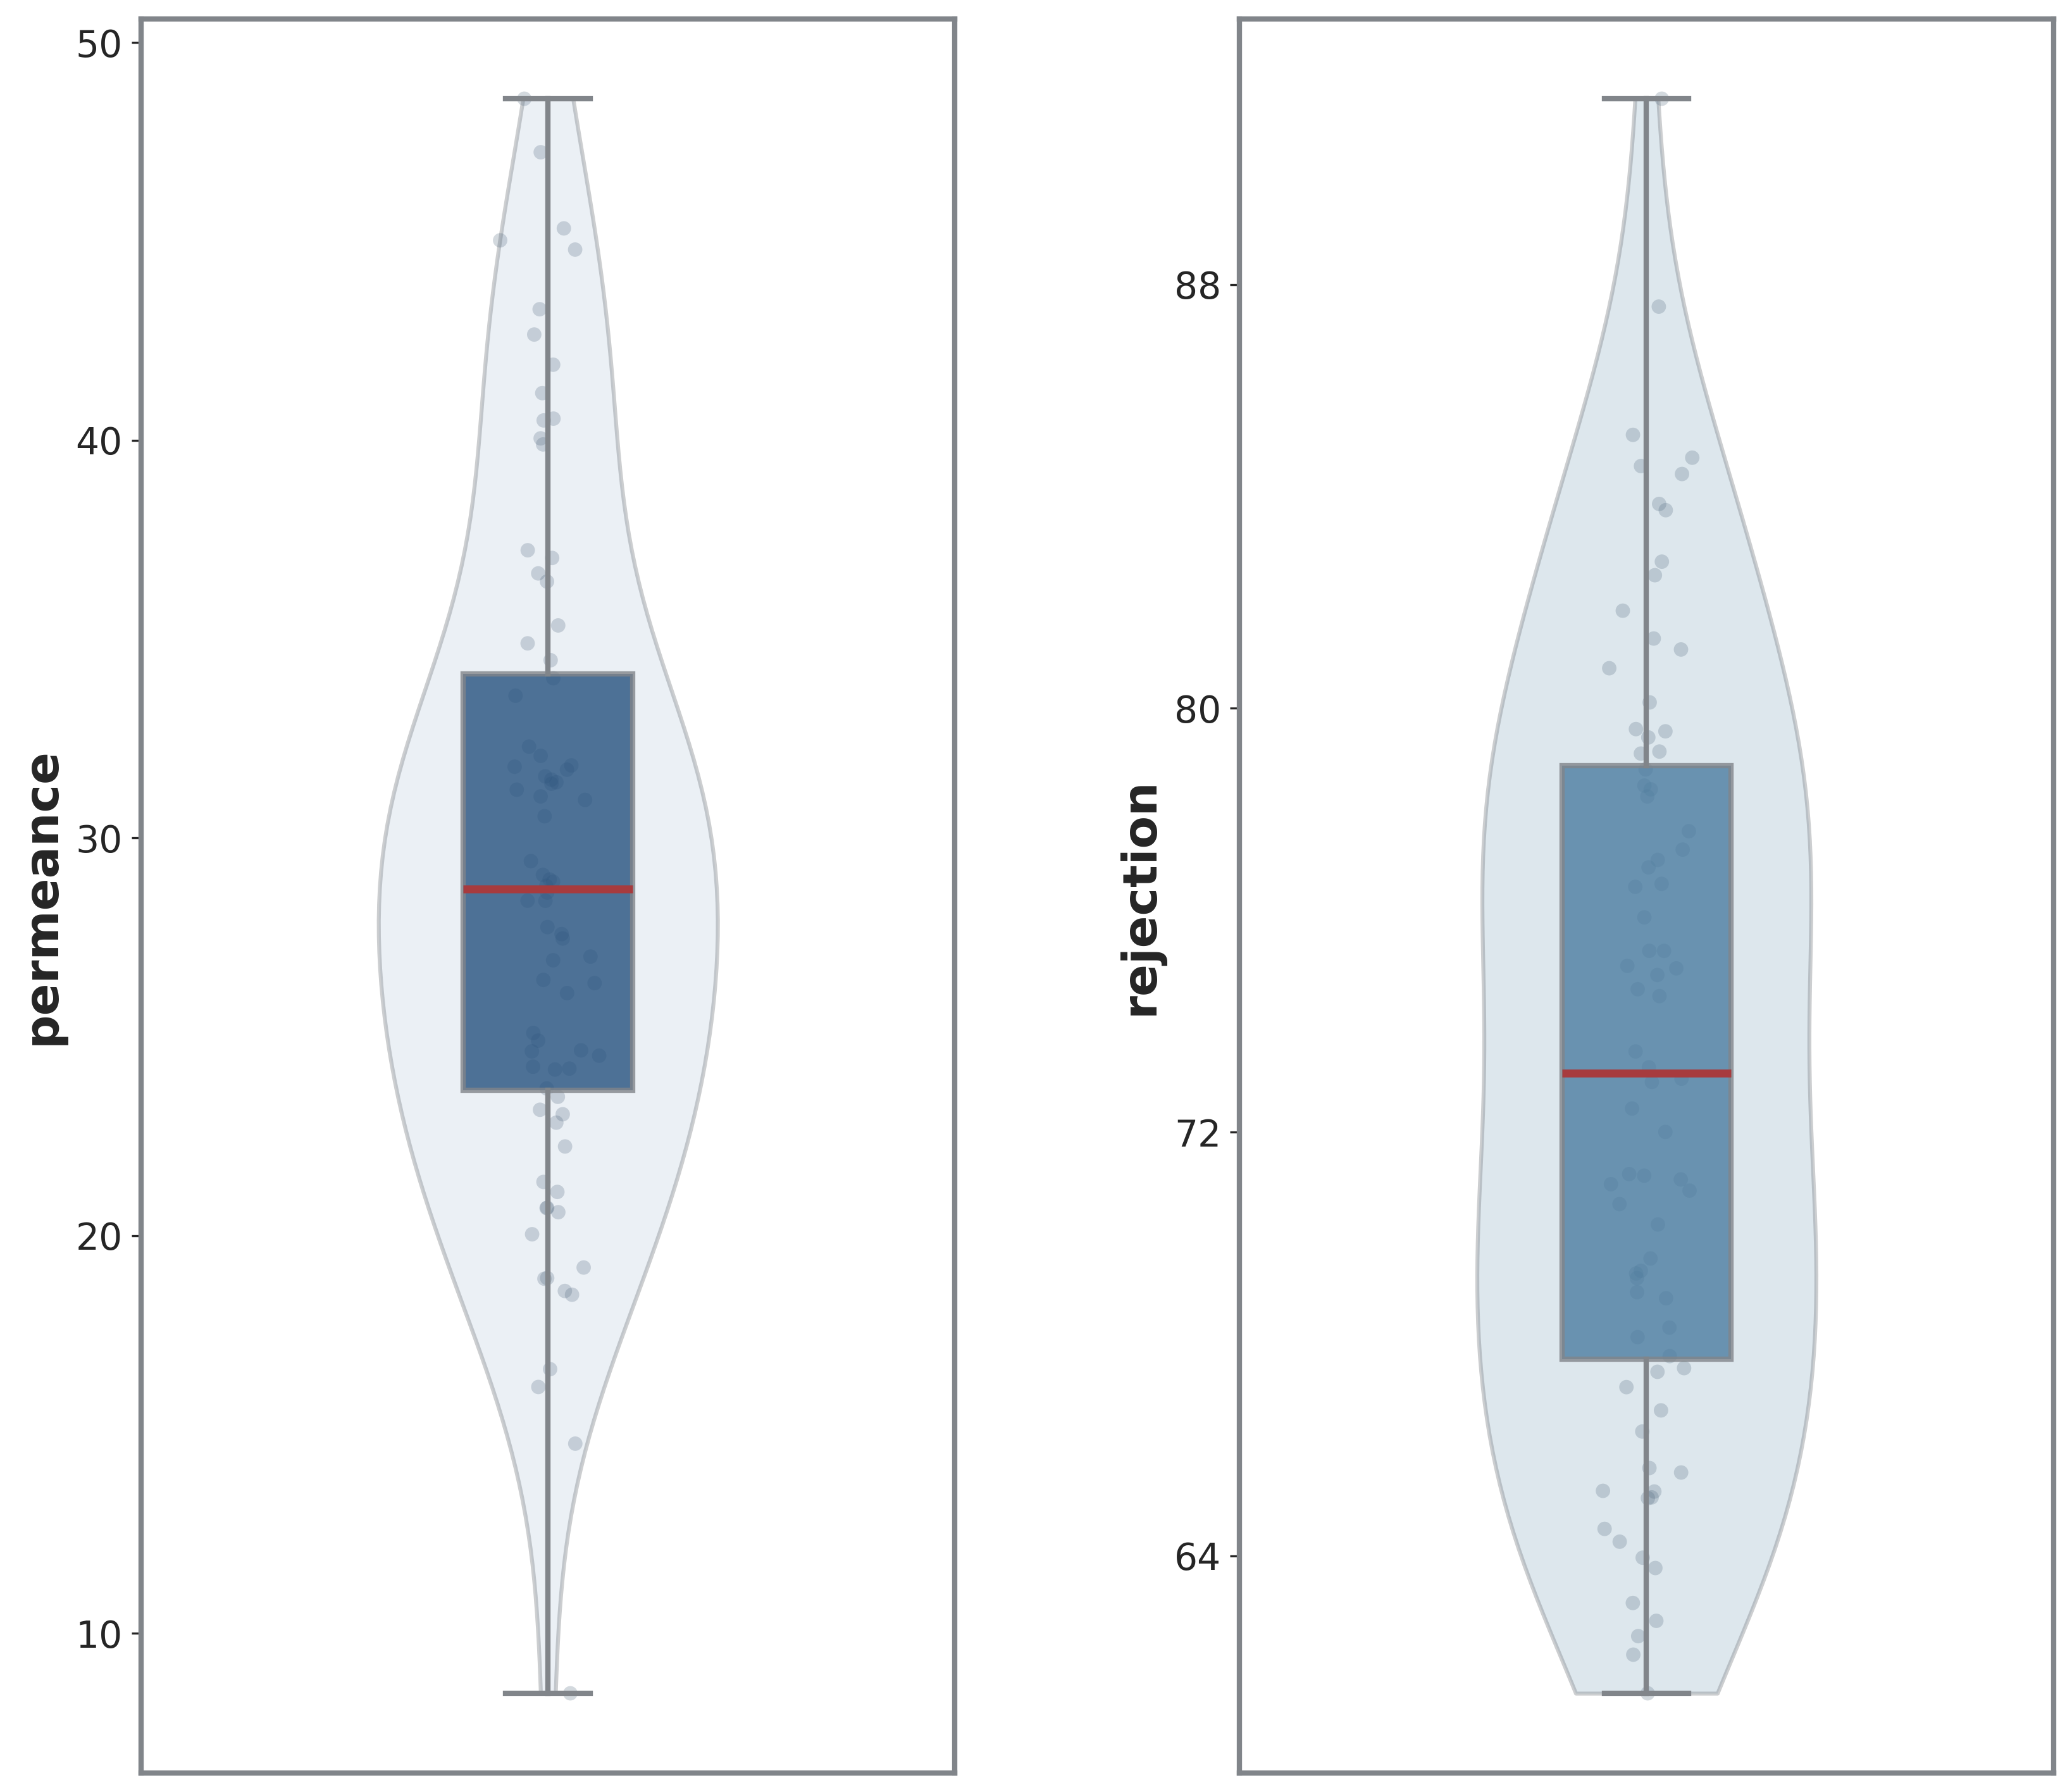

### pearson_heatmap.png

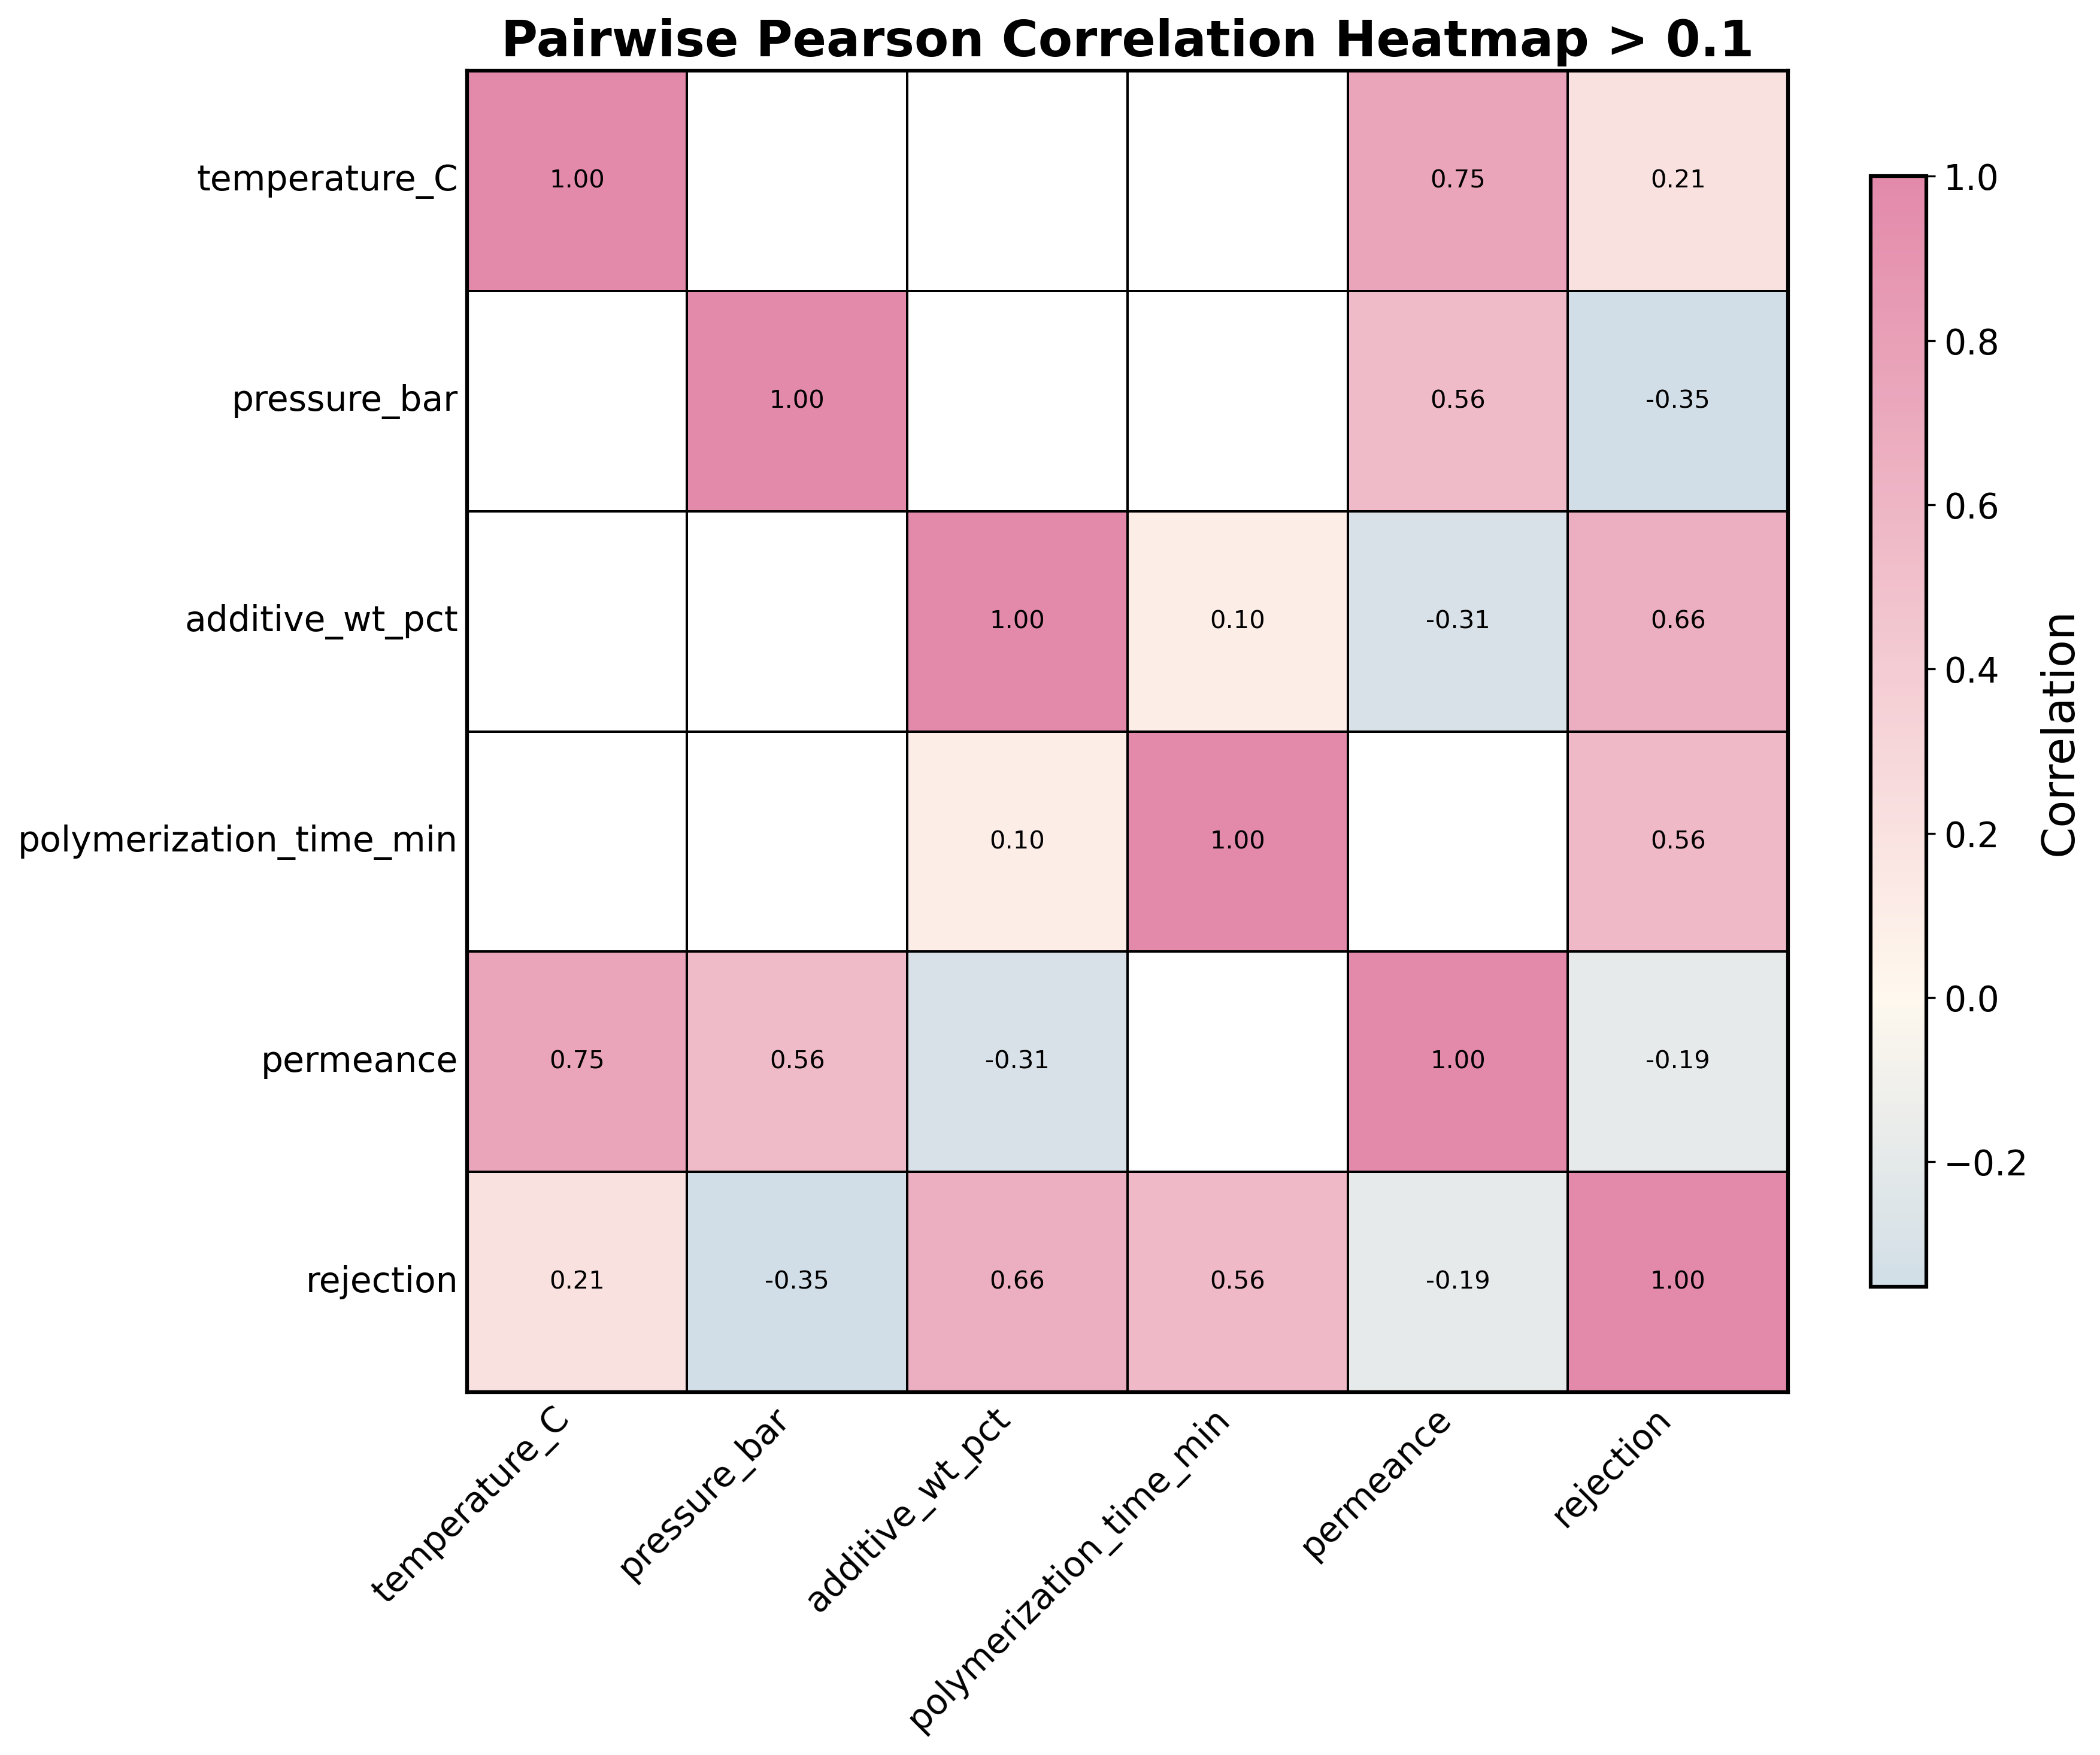

### parity_permeance.png

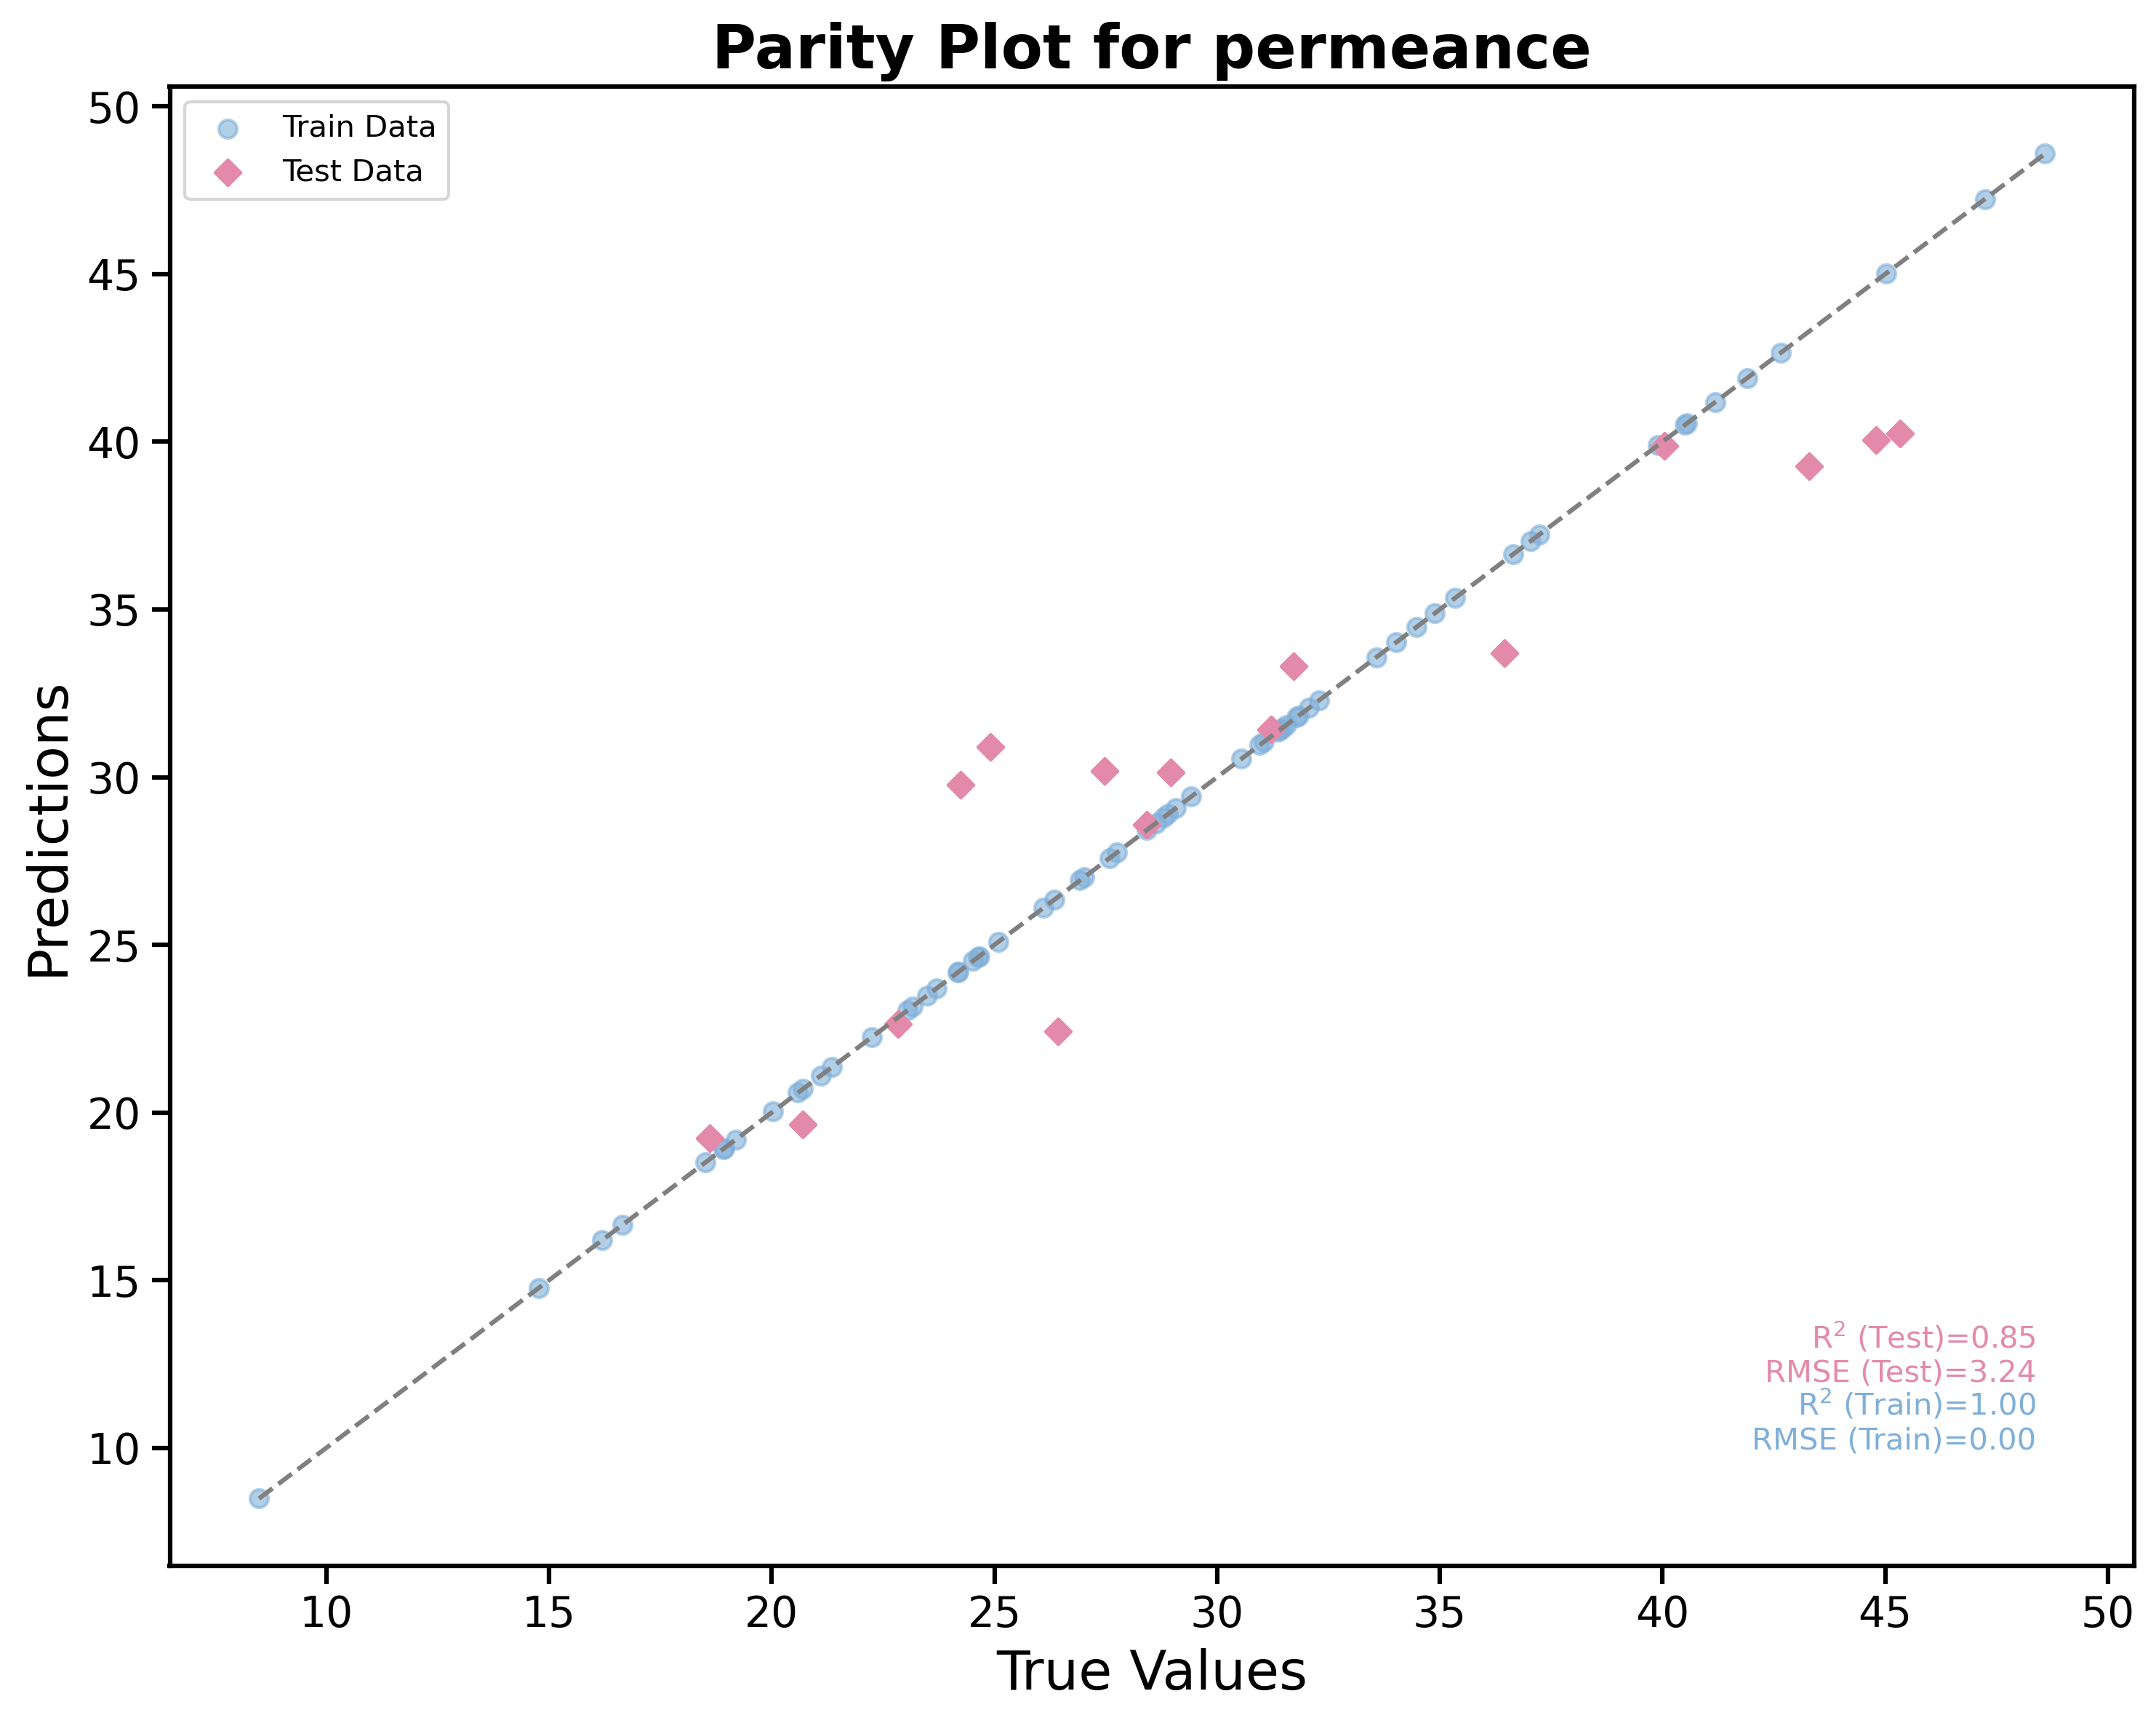

### parity_rejection.png

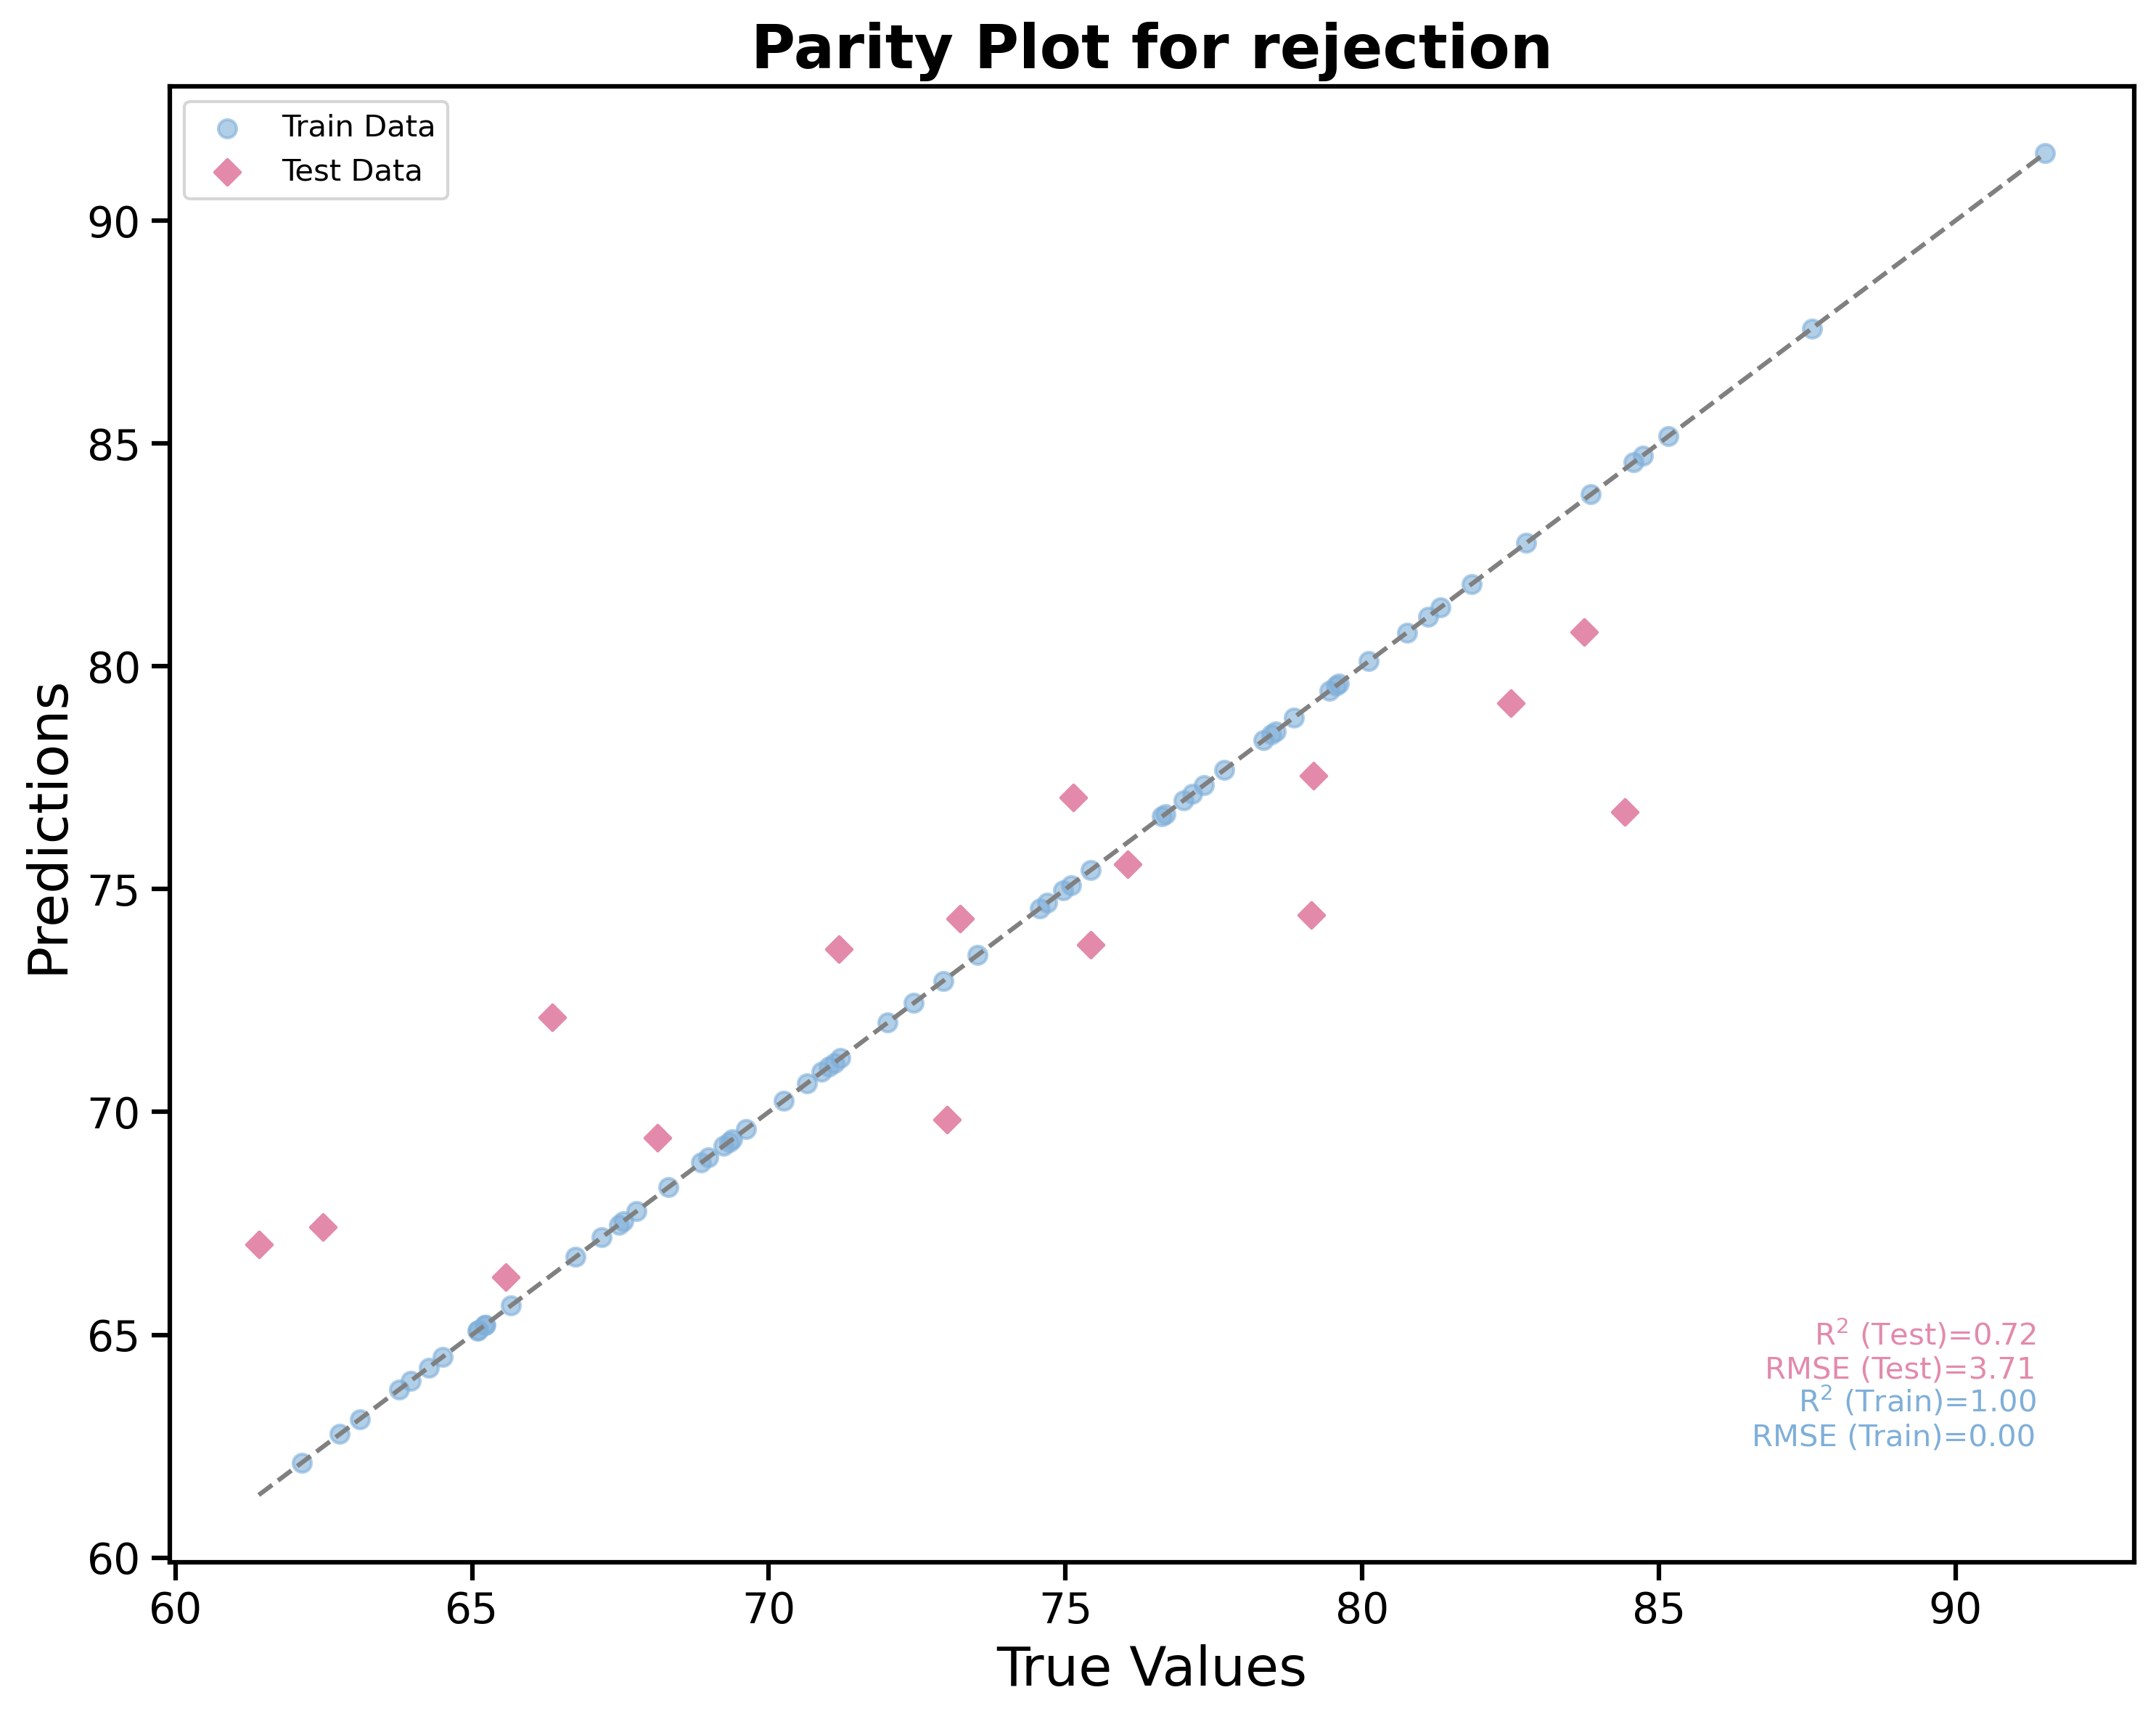

### inverse_design_summary.png

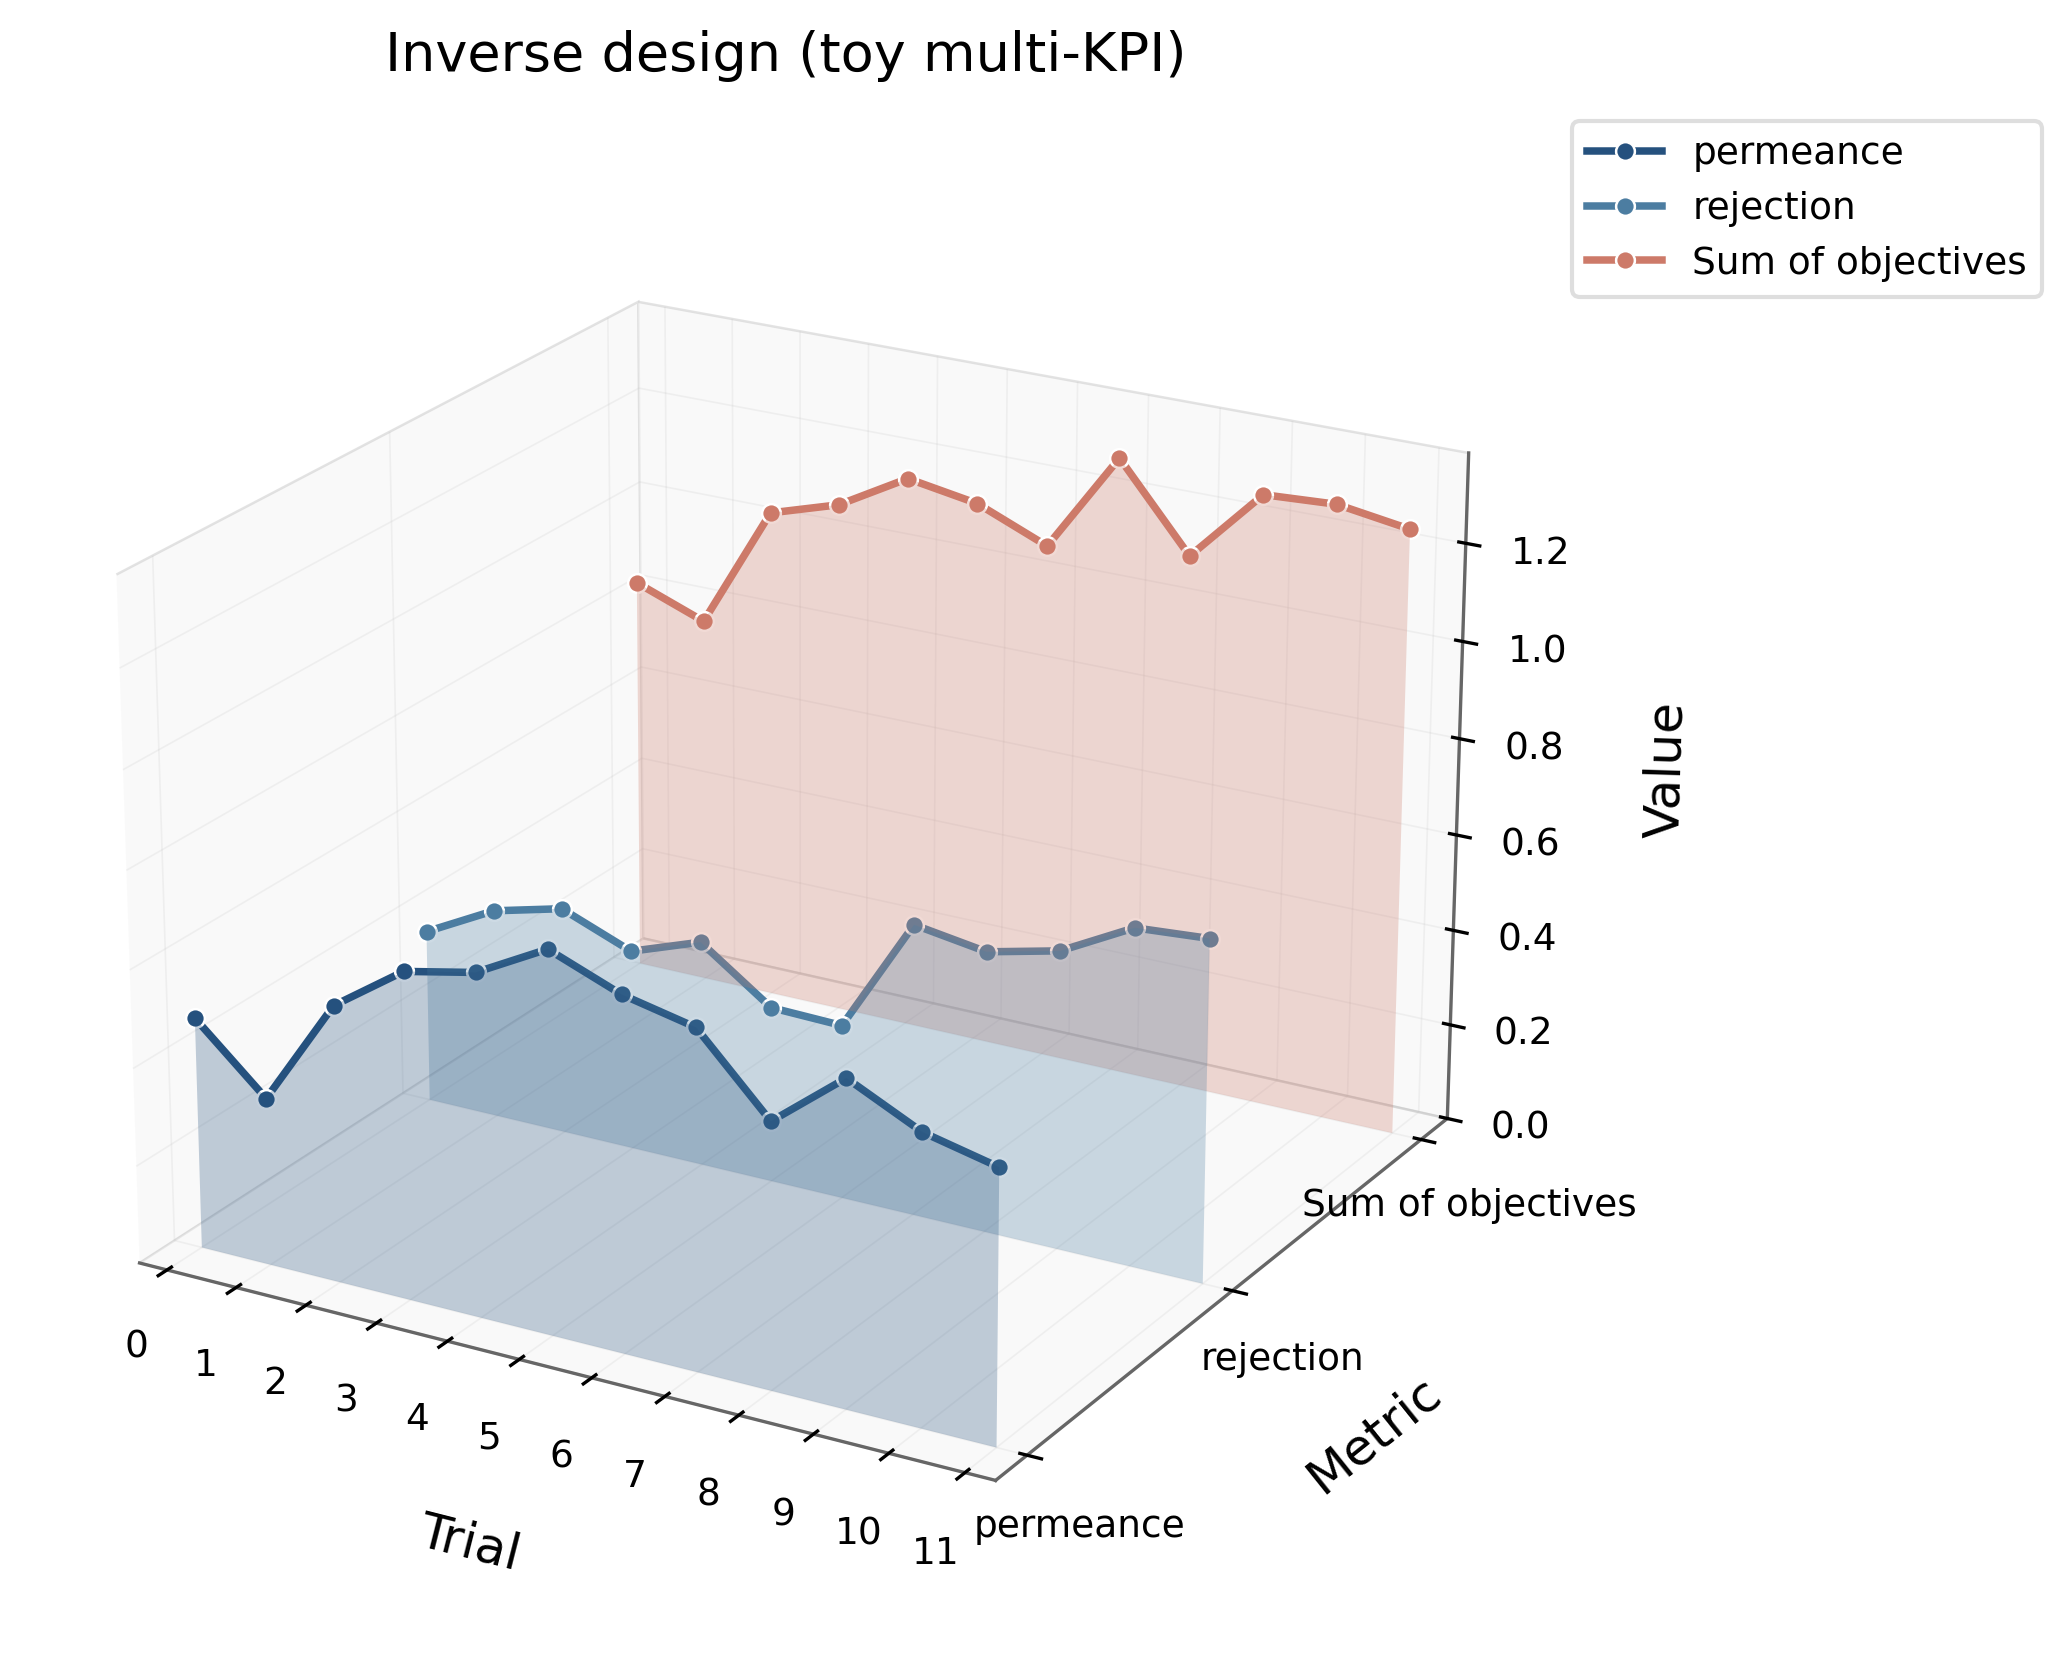

### response_map_1_contour.png

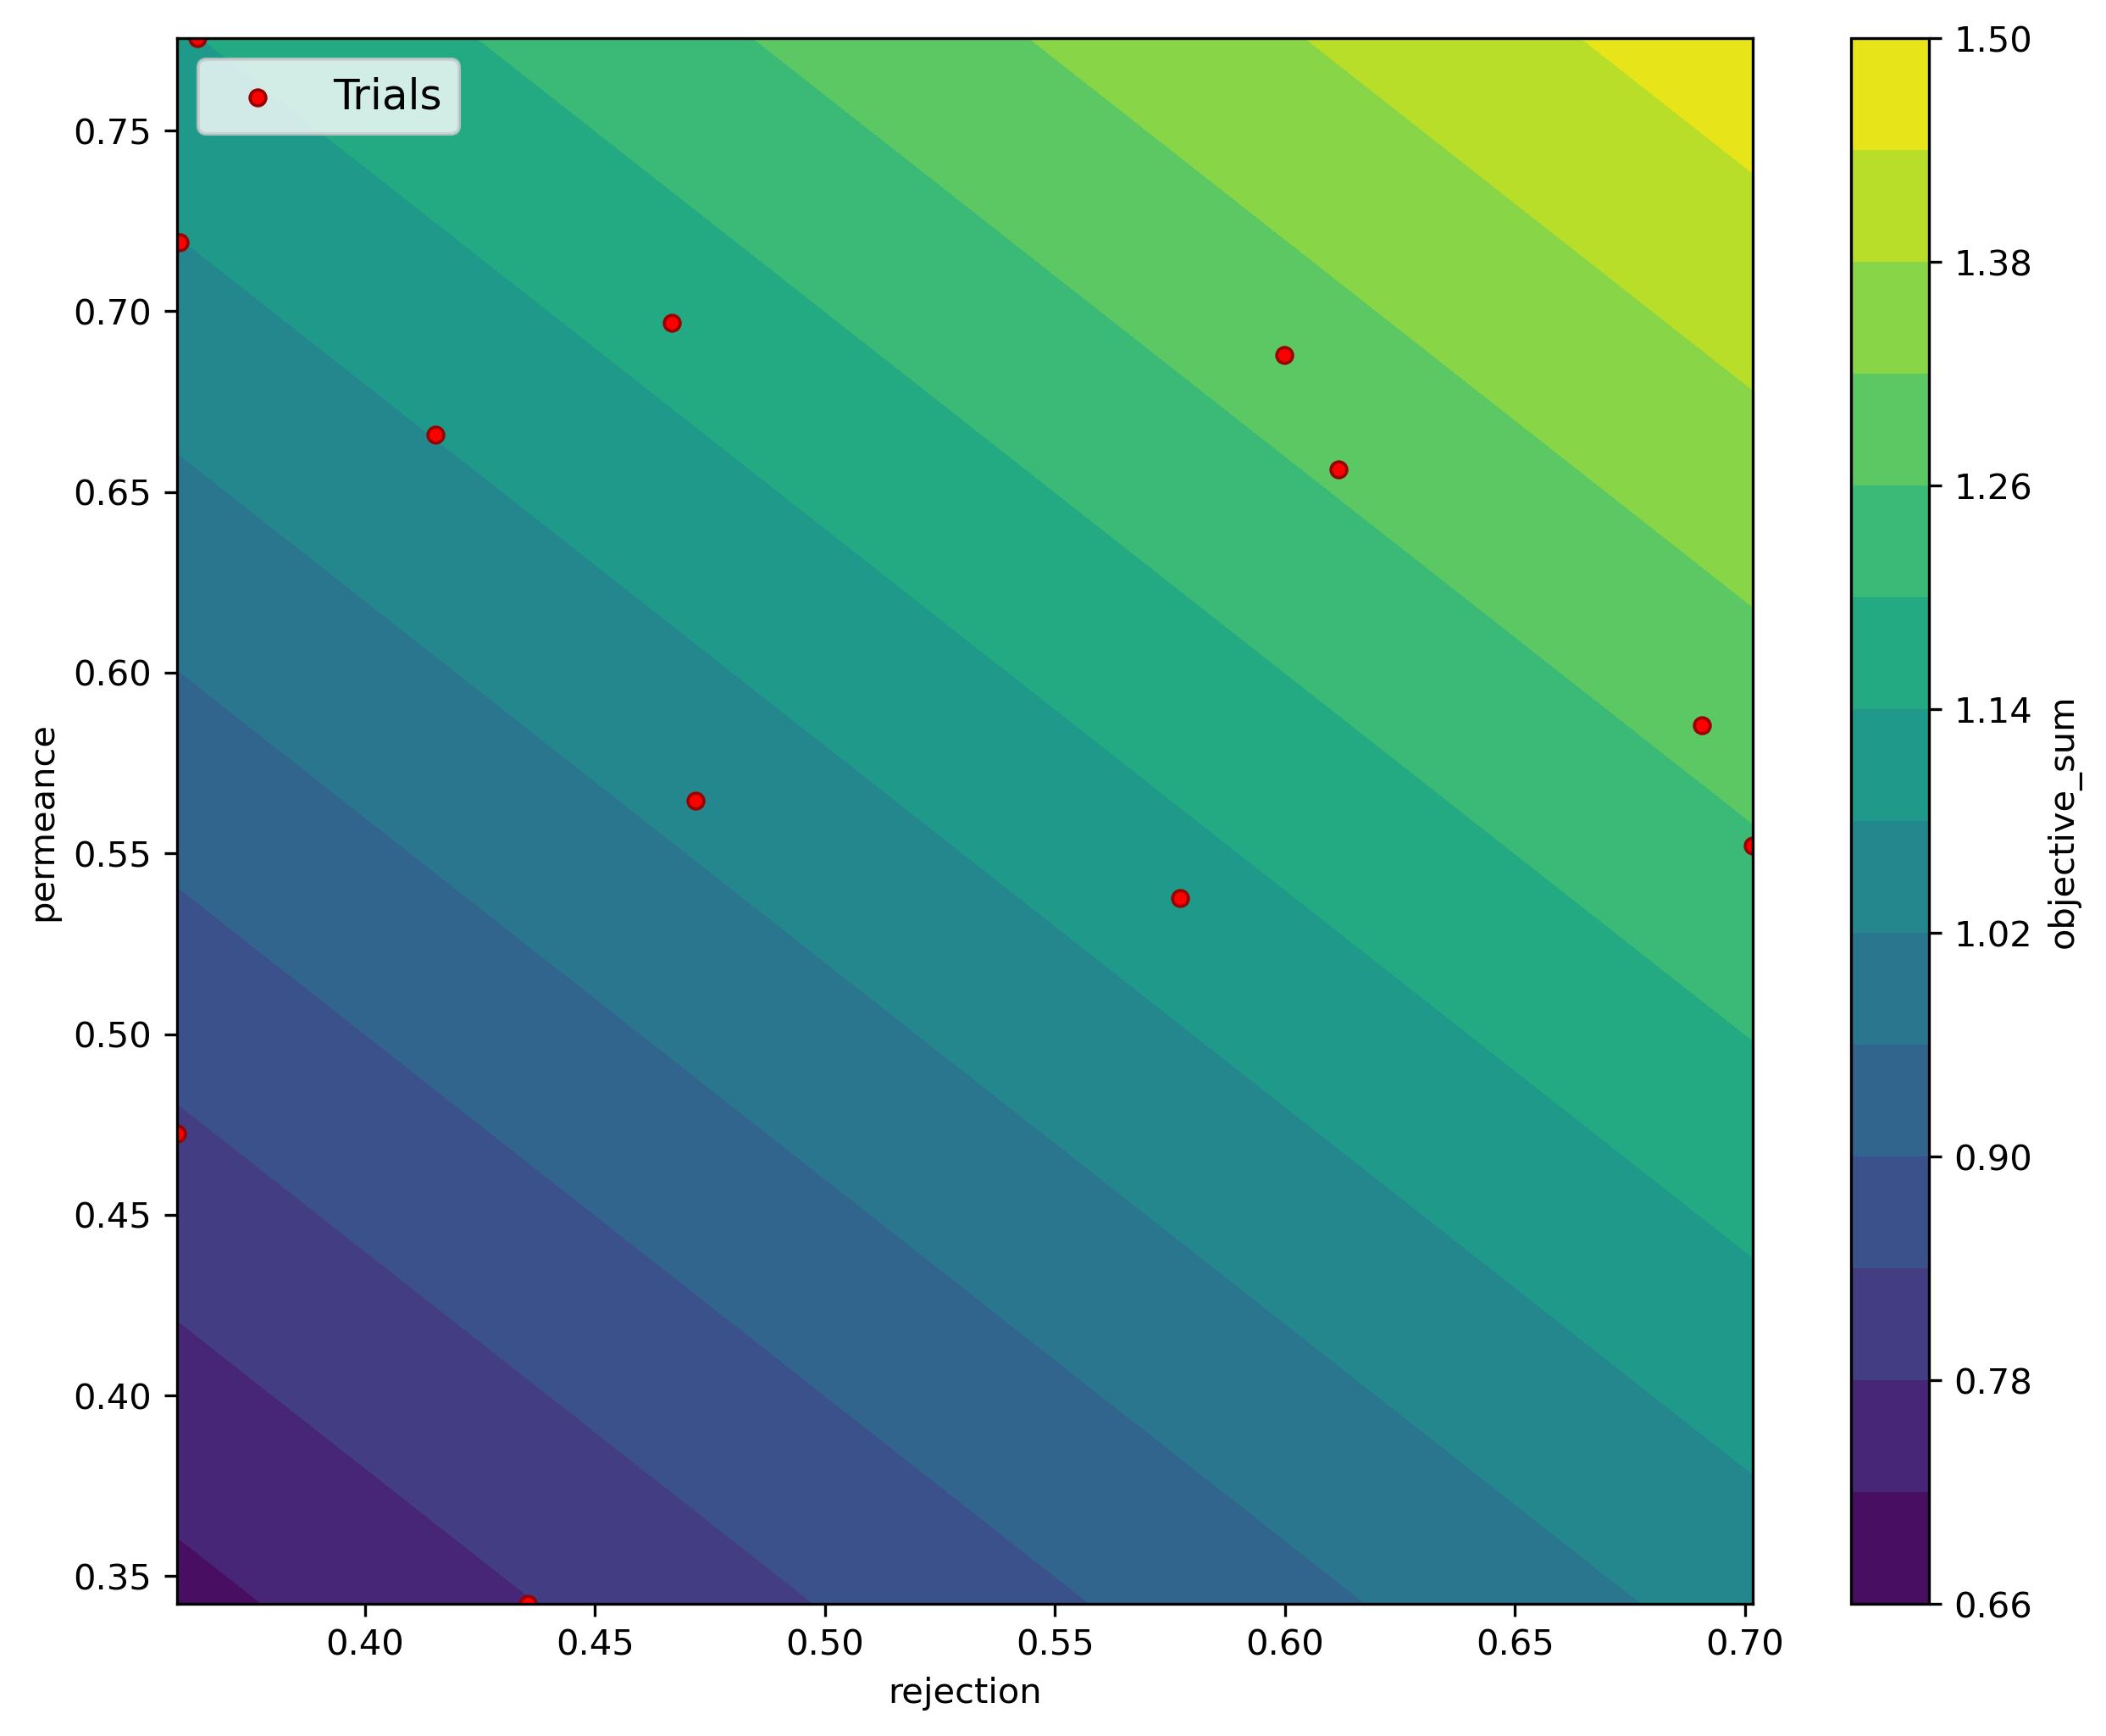

### response_map_1_surface.png

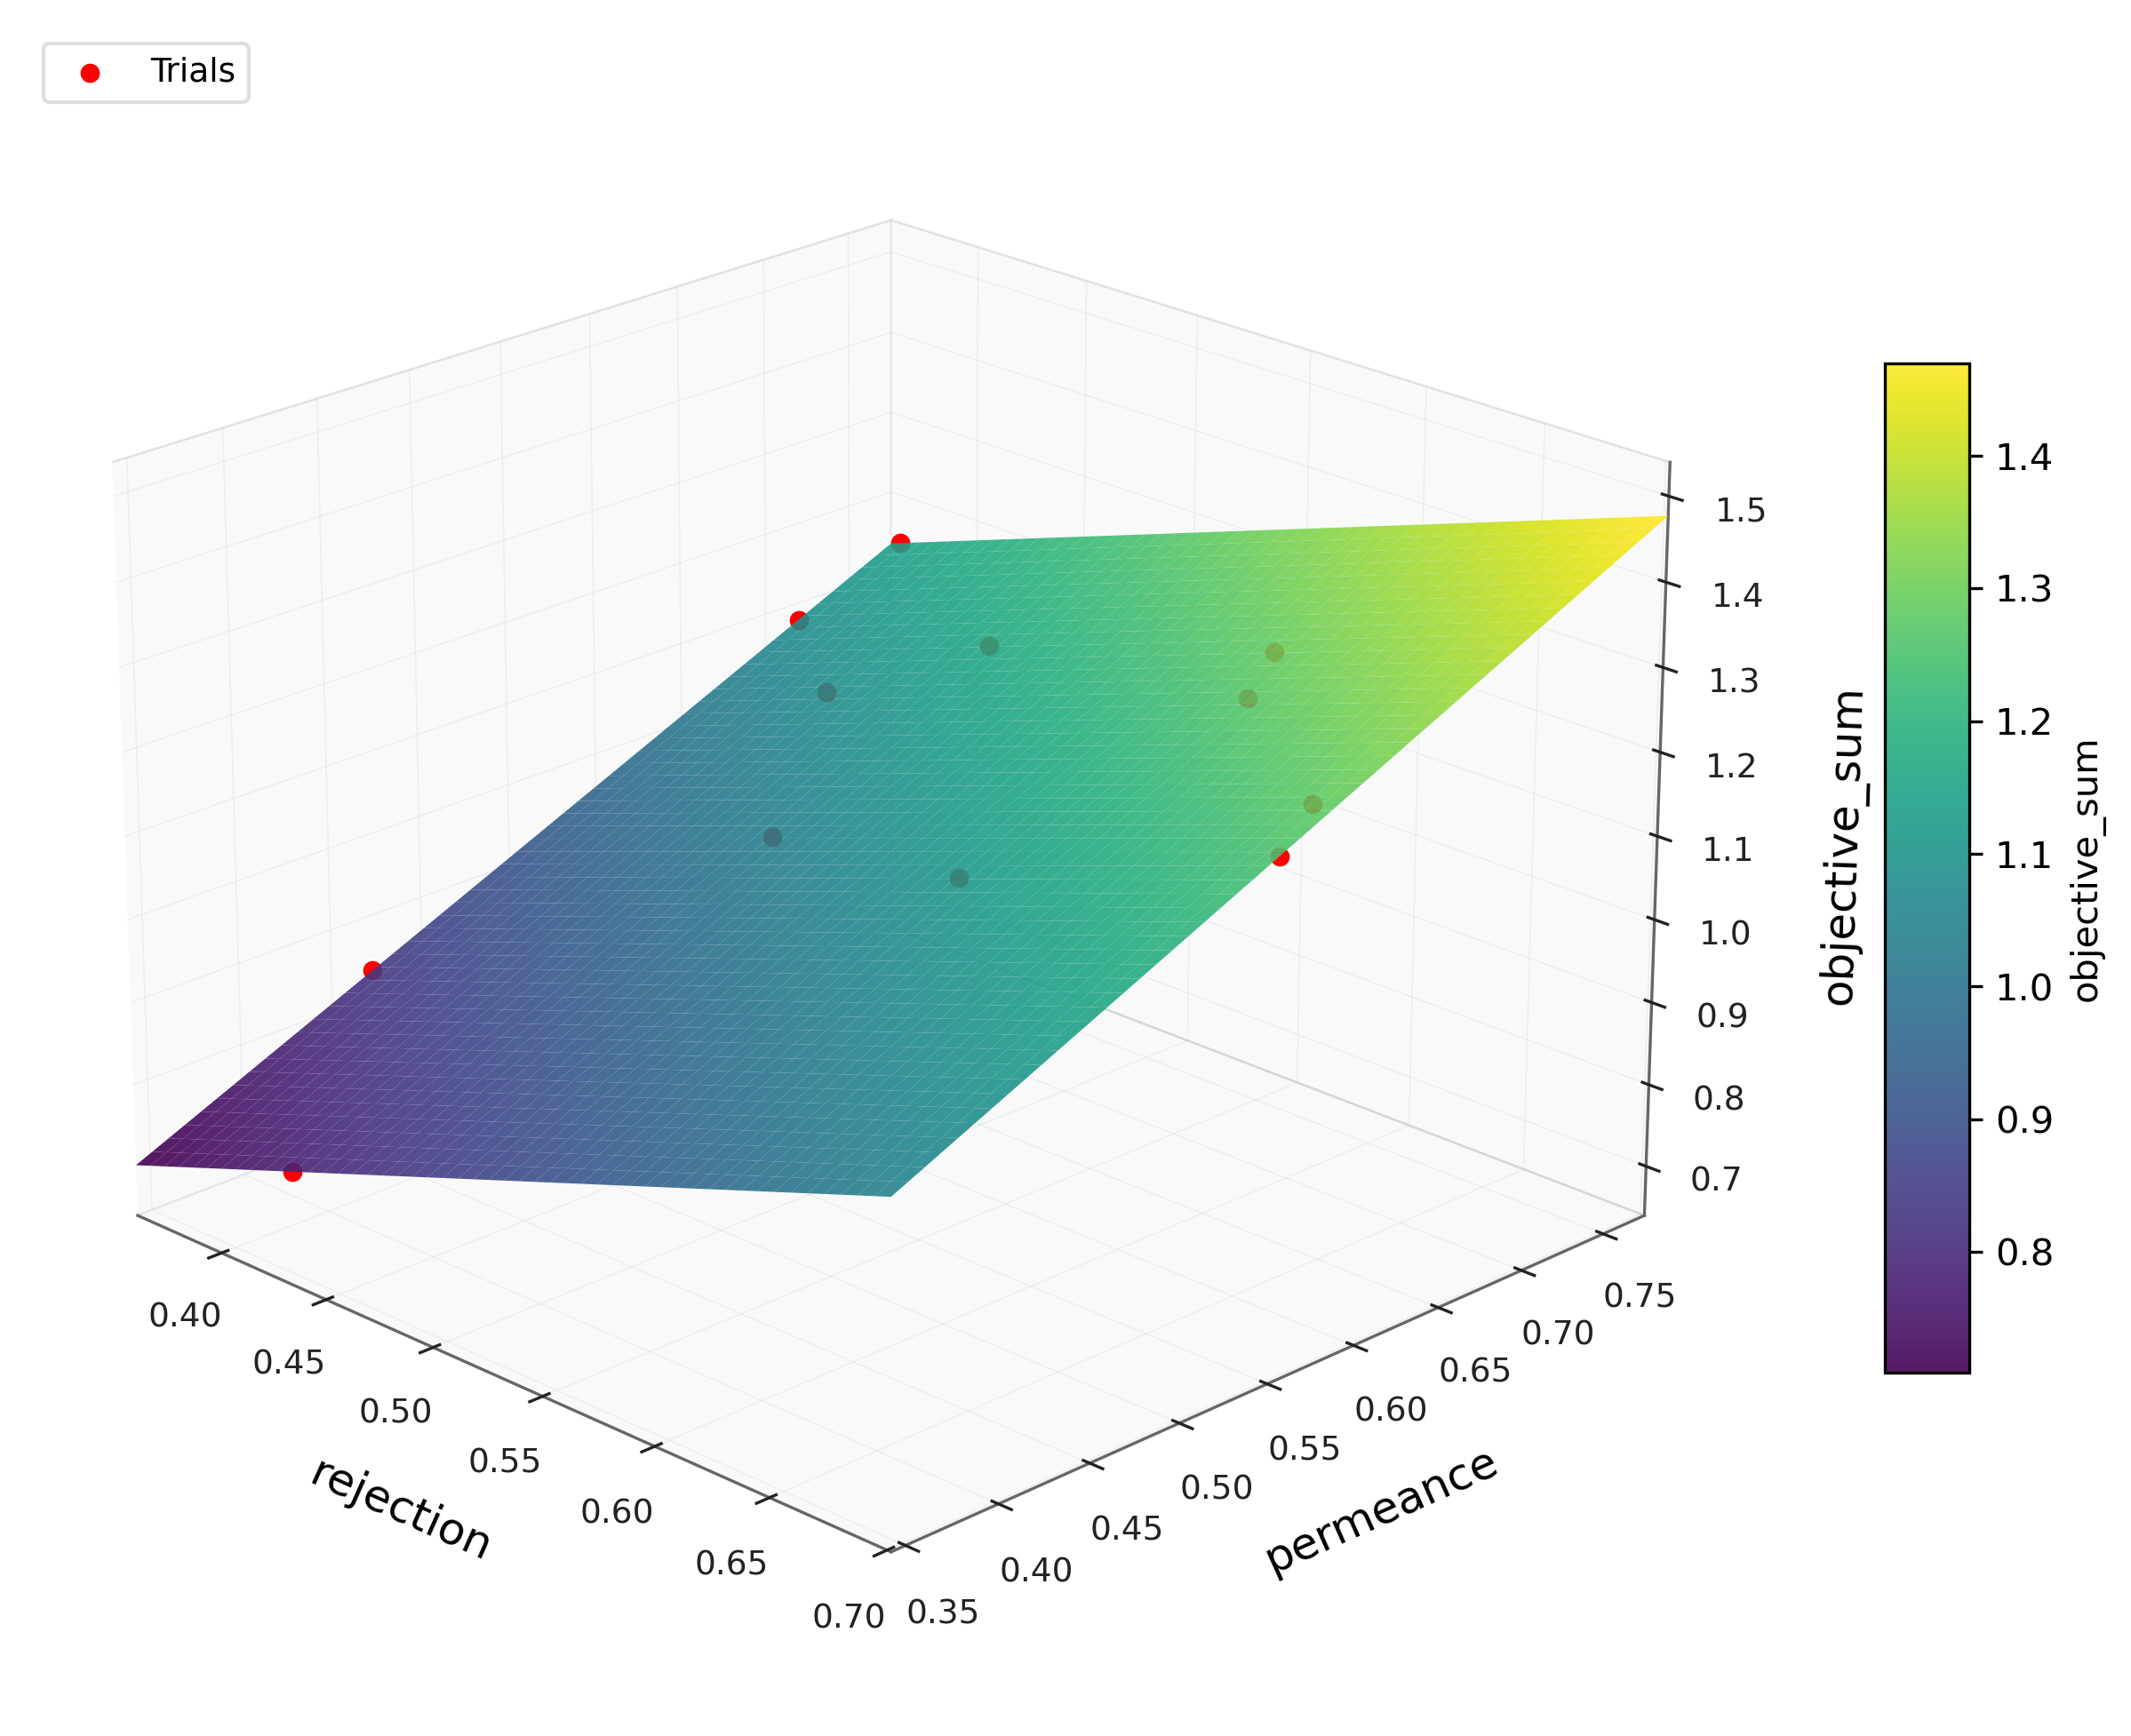

### response_map_2_contour.png

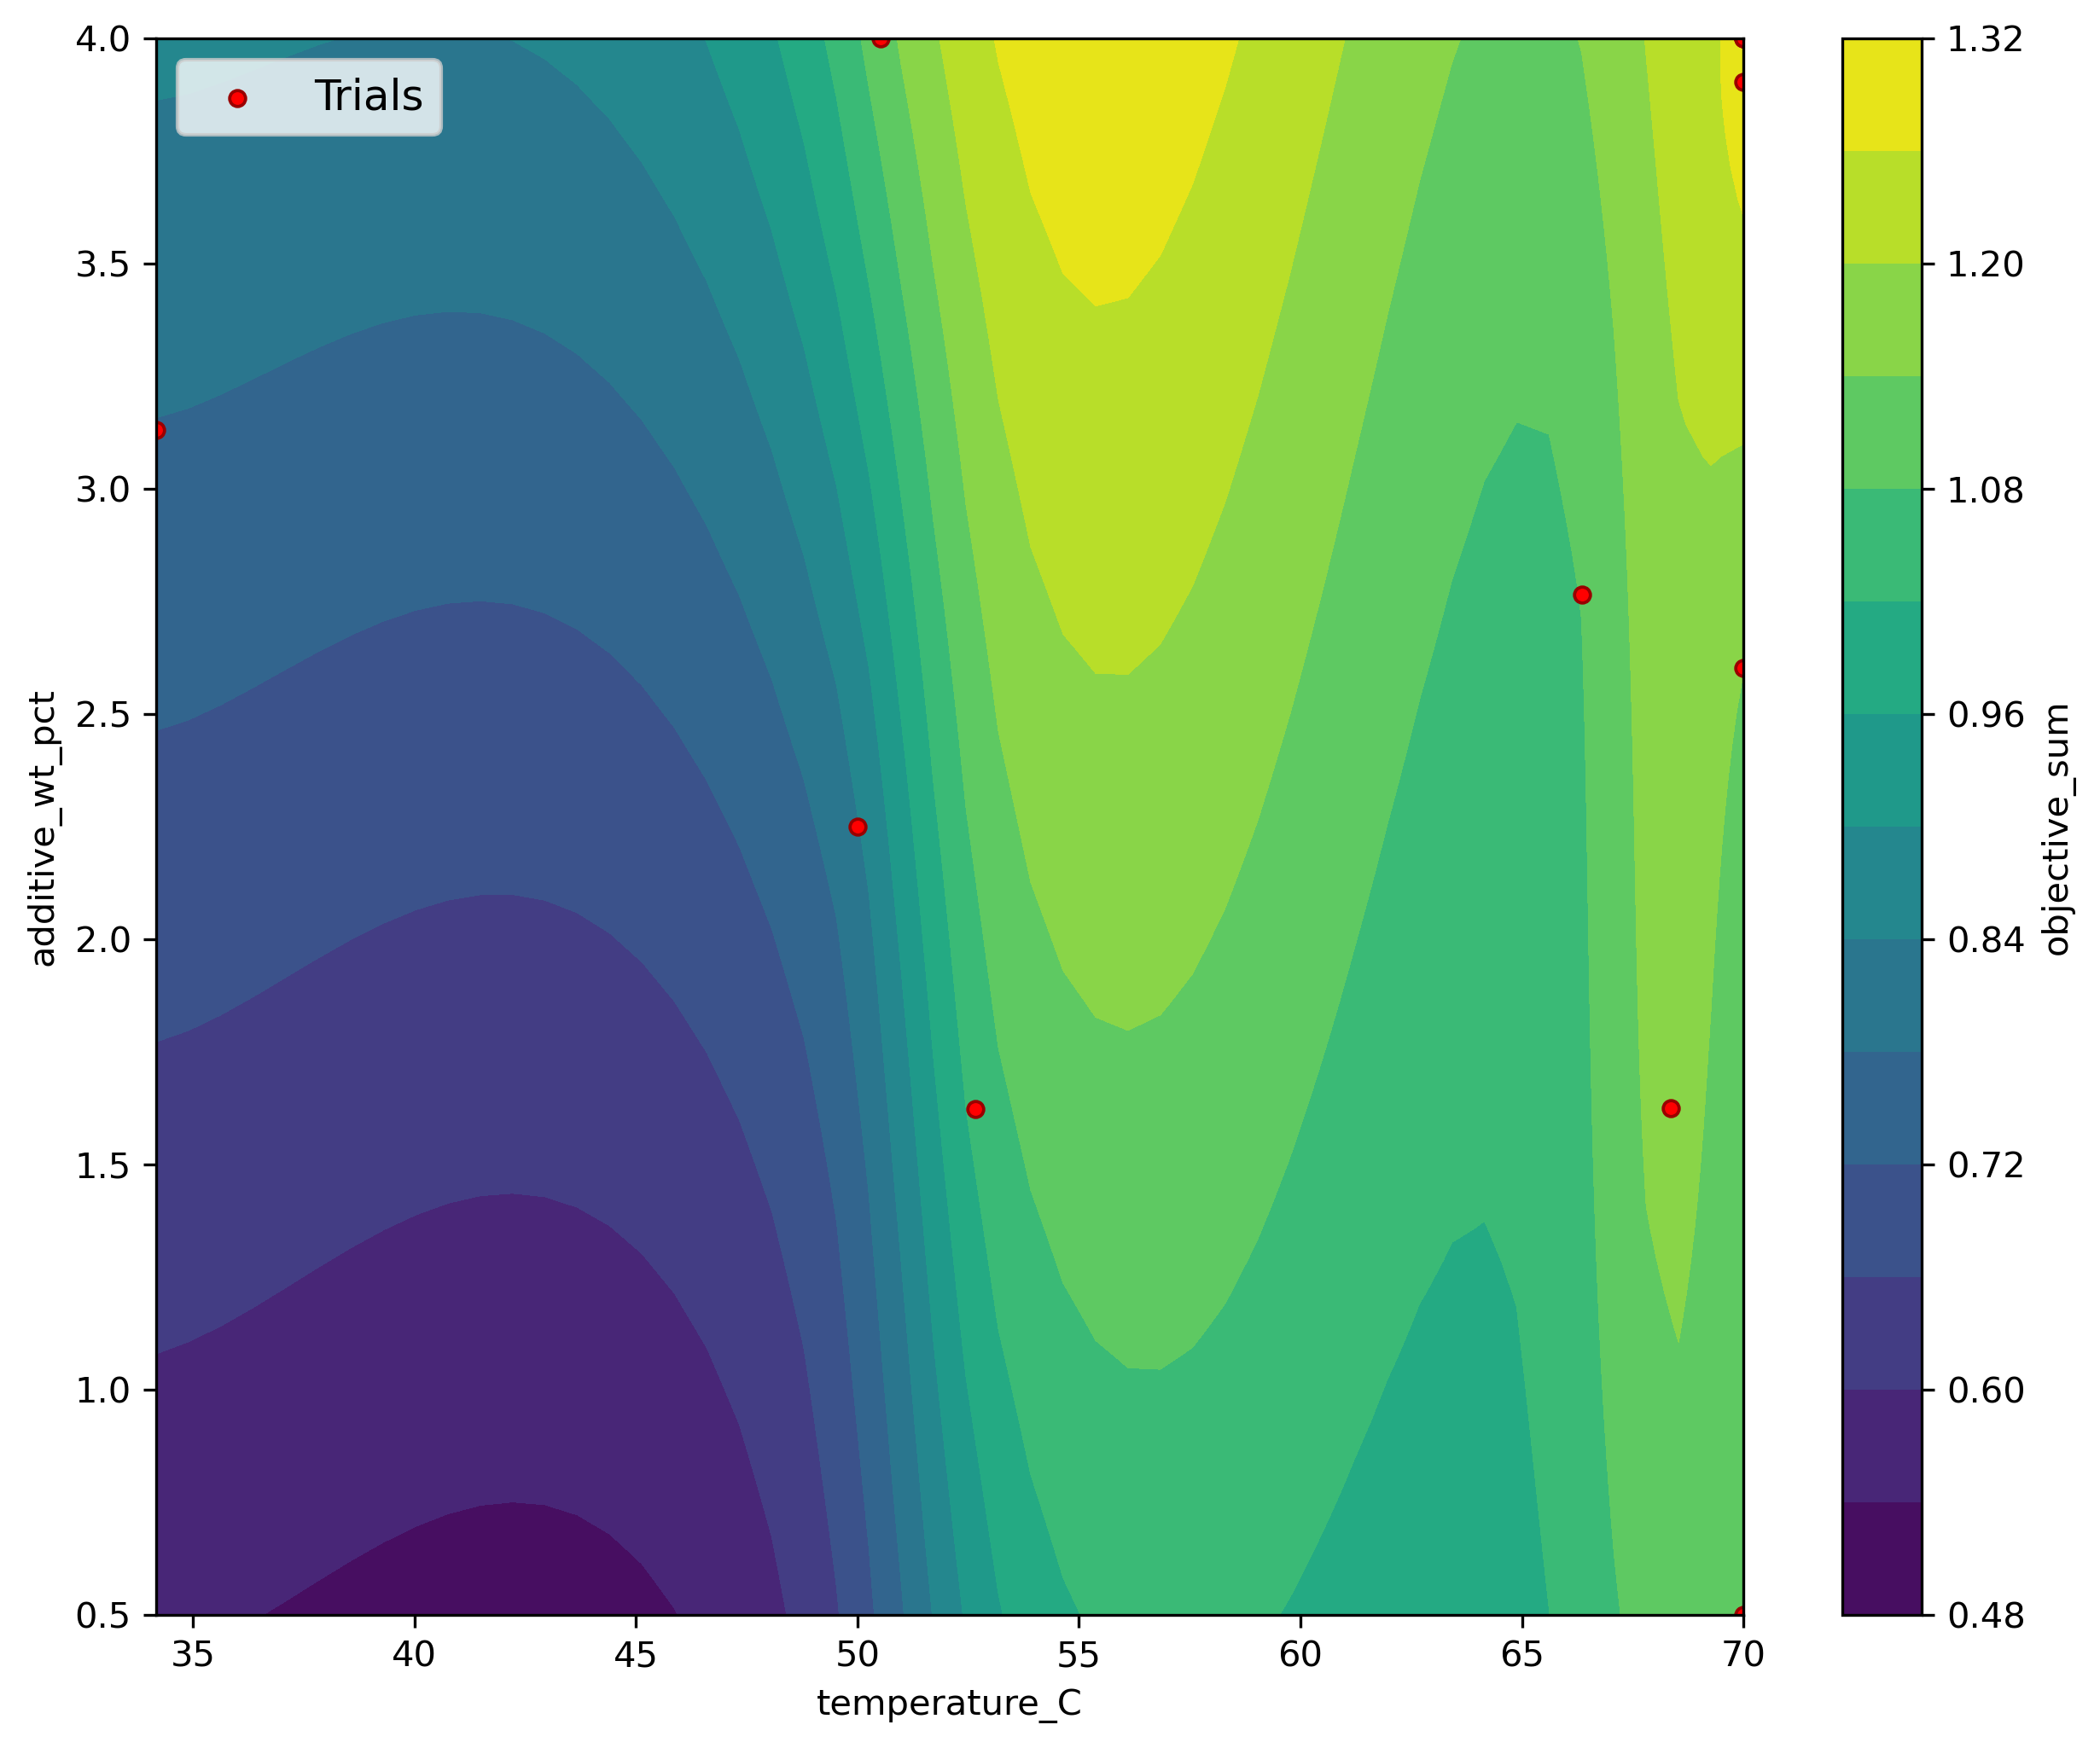

### response_map_2_surface.png

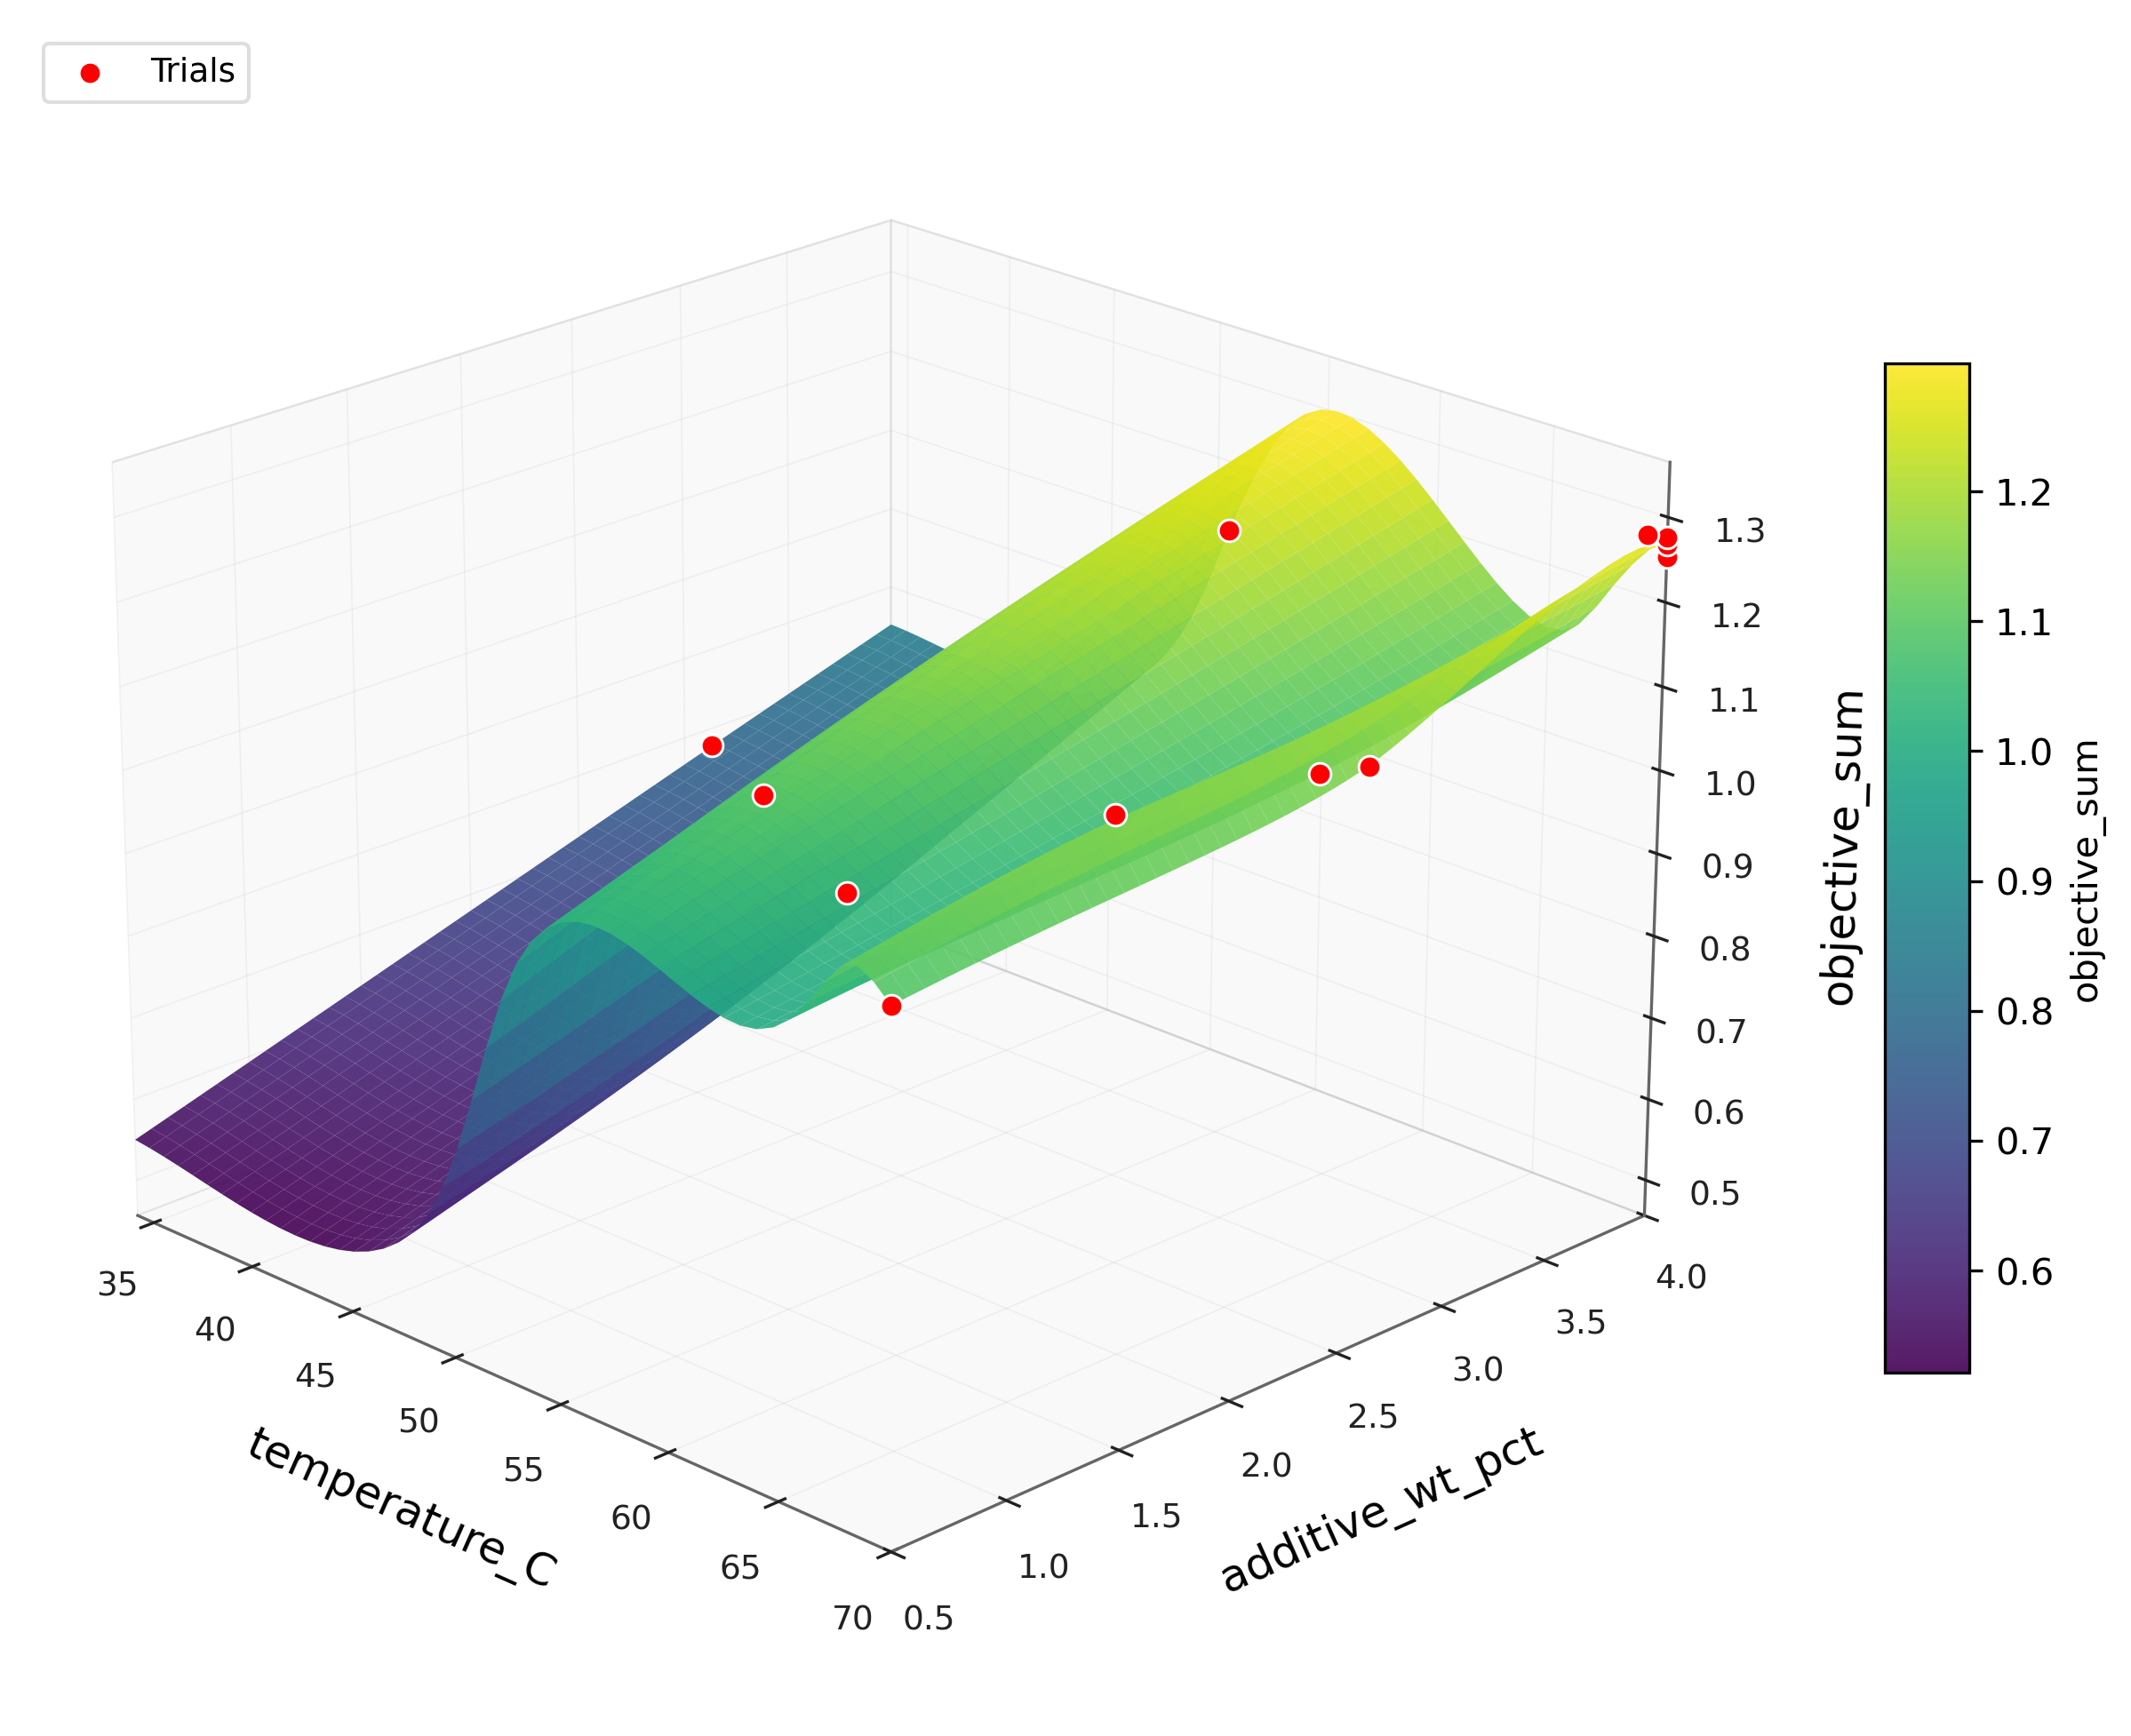

In [4]:
# @title Show figures
from pathlib import Path
from IPython.display import display, Markdown, Image

fig_dir = REPO_ROOT / "examples" / "05_inverse_design_controls" / "outputs" / "figures"
summary = fig_dir / "inverse_design_summary.png"
if not summary.is_file():
    raise FileNotFoundError(
        f"Missing {summary}. Inverse design did not run. "
        "Install Ax (`pip install -e '.[opt]'`) and re-run bootstrap."
    )
for name in [
    "target_distributions.png",
    "pearson_heatmap.png",
    "parity_permeance.png",
    "parity_rejection.png",
    "inverse_design_summary.png",
    "response_map_1_contour.png",
    "response_map_1_surface.png",
    "response_map_2_contour.png",
    "response_map_2_surface.png",
]:
    path = fig_dir / name
    if path.is_file():
        display(Markdown(f"### {name}"))
        display(Image(filename=str(path)))


## Try next

- Change the 0.3 / 0.7 weights; re-run the pipeline.
- Pareto: `mode: multiobjective` and uncomment `threshold` on each objective.
- Tighten `temperature_C` bounds.
- Tutorial §6: [`Ml-MEM-Tut.ipynb`](../../notebooks/Complete_notebook/Ml-MEM-Tut.ipynb)
